# Detekcja Phishingu - Regresja Logistyczna

Ten notebook zawiera implementację i analizę modelu regresji logistycznej do wykrywania phishingu.

## 1. Import bibliotek i konfiguracja


In [1]:
from pathlib import Path
import os
import sys

start_dir = Path.cwd().resolve()
backend_root = None
for candidate in (start_dir, *start_dir.parents):
    if (candidate / 'utils').is_dir() and (candidate / 'notebooks').is_dir():
        backend_root = candidate
        break
    nested_backend = candidate / 'backend'
    if (nested_backend / 'utils').is_dir() and (nested_backend / 'notebooks').is_dir():
        backend_root = nested_backend
        break

if backend_root is None:
    raise RuntimeError(
        f'Cannot locate backend root from Jupyter working directory: {start_dir}'
    )

notebooks_dir = backend_root / 'notebooks'
os.chdir(notebooks_dir)
if str(backend_root) not in sys.path:
    sys.path.insert(0, str(backend_root))

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import pickle
import importlib
import matplotlib.patches as mpatches

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, validation_curve, learning_curve, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                           roc_auc_score, confusion_matrix, log_loss)
from utils.feature_names import get_readable_name
from utils.split_dataset_loader import feature_columns
from utils.threshold_calibration import (
    calibrate_threshold, false_positive_rate, model_selection_score,
    DEFAULT_MAX_FALSE_POSITIVE_RATE, DEFAULT_MIN_RECALL,
)
if 'utils.resource_monitor' in sys.modules:
    importlib.reload(sys.modules['utils.resource_monitor'])
if 'utils.isolated_training' in sys.modules:
    importlib.reload(sys.modules['utils.isolated_training'])
from utils.isolated_training import fit_model_isolated
if 'utils.notebook_plot_style' in sys.modules:
    importlib.reload(sys.modules['utils.notebook_plot_style'])

from utils.notebook_plot_style import (
    plot_sample_probability_prediction,
    plot_training_time_comparison,
    save_comparison_figure,
    feature_count_comparison_rows,
    plot_final_train_test_metric_groups,
    resource_baseline_summary,
    classification_metric_sets,
    CLASS_COLORS,
    remove_dataset_figure,
    DATASET_SUBDIRS,
    dataset_display_name,
    dataset_key,
    plot_confusion_matrix,
    plot_parameter_train_validation_error,
    plot_roc_curve,
    plot_feature_ranking,
    plot_resource_usage_separate,
    plot_score_curve,
    save_dataset_figure,
)

from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Circle

PLOTS_DIR = backend_root.parent / 'results' / 'url_corpus' / 'plots' / 'logistic_regression'
MODELS_DIR = "../models/logistic_regression"
os.makedirs(PLOTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

DATASET_SUBDIR = DATASET_SUBDIRS
os.makedirs(f'{PLOTS_DIR}/full', exist_ok=True)
os.makedirs(f'{PLOTS_DIR}/optimized', exist_ok=True)

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['savefig.facecolor'] = 'white'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 16
plt.rcParams['figure.figsize'] = (12, 7)

np.random.seed(42)

print("Biblioteki zostały zaimportowane pomyślnie!")


Biblioteki zostały zaimportowane pomyślnie!


## 2. Wczytanie i eksploracja danych


In [2]:
from utils.split_dataset_loader import (
    build_train_test_data,
    feature_columns,
    load_split_frames,
    print_split_summary,
)

QUALITY_SPLIT_DIR = backend_root / 'data' / 'url_corpus' / 'quality_v4_repaired_features'
split_frames = {
    'Pełny zbiór': load_split_frames(QUALITY_SPLIT_DIR, 'dataset_full'),
    'Zoptymalizowany zbiór': load_split_frames(QUALITY_SPLIT_DIR, 'dataset_optimized'),
}
print_split_summary(split_frames)
datasets = split_frames


DANE ZAŁADOWANE - PREDEFINED DOMAIN/TEMPLATE SPLITS

Pełny zbiór:
  • train: 108,762 rows, 110 features, safe=54,381, phishing=54,381
  • val: 21,676 rows, 110 features, safe=10,838, phishing=10,838
  • test: 21,000 rows, 110 features, safe=10,500, phishing=10,500

Zoptymalizowany zbiór:
  • train: 108,762 rows, 47 features, safe=54,381, phishing=54,381
  • val: 21,676 rows, 47 features, safe=10,838, phishing=10,838
  • test: 21,000 rows, 47 features, safe=10,500, phishing=10,500

Uwaga: zbiory URL-corpus są celowo zbalansowane (50% bezpiecznych, 50% phishingowych) na potrzeby kontrolowanego porównania algorytmów.
Wyników precision i accuracy nie należy bezpośrednio interpretować jako częstości błędów w ruchu produkcyjnym.

No random train_test_split is used for URL corpus notebooks.


## 3. Przygotowanie cech i etykiet


In [3]:
data_splits = {}

for name, frames in datasets.items():
    train_df = frames['train']
    model_feature_columns = feature_columns(train_df)
    train_class_counts = train_df['phishing'].value_counts()
    positive_count = int(train_class_counts.get(1, 0))
    if positive_count == 0:
        raise ValueError(f'Brak klasy phishing w treningowym splicie: {name}')
    scale_pos_weight = float(train_class_counts.get(0, 0) / positive_count)

    data_splits[name] = {
        'frames': frames,
        'X': train_df[model_feature_columns],
        'y': train_df['phishing'],
        'feature_columns': model_feature_columns,
        'feature_count': len(model_feature_columns),
        'scale_pos_weight': scale_pos_weight,
    }

    print(f"\n{name}:")
    print(f"  • Liczba cech: {len(model_feature_columns)}")
    for split_name, df in frames.items():
        counts = df['phishing'].value_counts()
        print(f"  • {split_name}: {len(df):,} próbek")
        print(f"    - Brak phishingu: {counts.get(0, 0):,}")
        print(f"    - Phishing: {counts.get(1, 0):,}")



Pełny zbiór:
  • Liczba cech: 110
  • train: 108,762 próbek
    - Brak phishingu: 54,381
    - Phishing: 54,381
  • val: 21,676 próbek
    - Brak phishingu: 10,838
    - Phishing: 10,838
  • test: 21,000 próbek
    - Brak phishingu: 10,500
    - Phishing: 10,500

Zoptymalizowany zbiór:
  • Liczba cech: 47
  • train: 108,762 próbek
    - Brak phishingu: 54,381
    - Phishing: 54,381
  • val: 21,676 próbek
    - Brak phishingu: 10,838
    - Phishing: 10,838
  • test: 21,000 próbek
    - Brak phishingu: 10,500
    - Phishing: 10,500


## 4. Podział danych i standaryzacja


In [4]:
from sklearn.preprocessing import StandardScaler

train_test_data = build_train_test_data(datasets)

for name, data in train_test_data.items():
    X_train = data['X_train']
    X_val = data['X_val']
    X_test = data['X_test']
    y_train = data['y_train']
    y_val = data['y_val']
    y_test = data['y_test']

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test)

    data_splits[name]['X'] = X_train
    data_splits[name]['y'] = y_train
    data_splits[name]['X_train'] = X_train
    data_splits[name]['X_val'] = X_val
    data_splits[name]['X_test'] = X_test
    data_splits[name]['y_train'] = y_train
    data_splits[name]['y_val'] = y_val
    data_splits[name]['y_test'] = y_test
    data_splits[name]['X_train_scaled'] = X_train_scaled
    data_splits[name]['X_val_scaled'] = X_val_scaled
    data_splits[name]['X_test_scaled'] = X_test_scaled
    data_splits[name]['scaler'] = scaler

    print(f"\n{name}:")
    print(f"  • Zbiór uczący: {X_train.shape[0]:,} próbek")
    print(f"  • Zbiór do testowania podczas uczenia: {X_val.shape[0]:,} próbek")
    print(f"  • Końcowy zbiór testowy: {X_test.shape[0]:,} próbek")
    print("  • Podział pochodzi z plików quality_v4_repaired_features; train_test_split nie jest używany.")

    train_counts = y_train.value_counts()
    print(f"  • Rozkład klas (uczący):")
    print(f"    - Brak phishingu: {train_counts.get(0, 0):,}")
    print(f"    - Phishing: {train_counts.get(1, 0):,}")



Pełny zbiór:
  • Zbiór uczący: 108,762 próbek
  • Zbiór do testowania podczas uczenia: 21,676 próbek
  • Końcowy zbiór testowy: 21,000 próbek
  • Podział pochodzi z plików quality_v4_repaired_features; train_test_split nie jest używany.
  • Rozkład klas (uczący):
    - Brak phishingu: 54,381
    - Phishing: 54,381

Zoptymalizowany zbiór:
  • Zbiór uczący: 108,762 próbek
  • Zbiór do testowania podczas uczenia: 21,676 próbek
  • Końcowy zbiór testowy: 21,000 próbek
  • Podział pochodzi z plików quality_v4_repaired_features; train_test_split nie jest używany.
  • Rozkład klas (uczący):
    - Brak phishingu: 54,381
    - Phishing: 54,381


## 5. Optymalizacja hiperparametrów i trening modelu


In [5]:
param_grids = [
    {
        'name': 'Optymalizacja parametru C (solver=liblinear)',
        'params': {
            'C': [0.01, 0.1, 1, 10, 100],
            'solver': ['liblinear'],
            'max_iter': [1000],
            'class_weight': [None, 'balanced', {0: 1.0, 1: 1.25}]
        }
    },
    {
        'name': 'Optymalizacja parametru C (solver=lbfgs)',
        'params': {
            'C': [0.1, 1, 10],
            'solver': ['lbfgs'],
            'max_iter': [1000, 2000],
            'class_weight': [None, 'balanced', {0: 1.0, 1: 1.25}]
        }
    },
    {
        'name': 'Optymalizacja parametru C (solver=saga)',
        'params': {
            'C': [0.1, 1, 10],
            'solver': ['saga'],
            'max_iter': [1000, 2000],
            'class_weight': [None, 'balanced', {0: 1.0, 1: 1.25}]
        }
    }
]

trained_models = {}

for dataset_name, data in train_test_data.items():
    print(f"\n{'='*80}")
    print(f"UCZENIE MODELU - {dataset_name.upper()}")
    print(f"{'='*80}")

    X_train_scaled = data['X_train_scaled']
    y_train = data['y_train']

    best_overall_score = 0
    best_overall_model = None
    best_overall_params = None
    best_config_name = ""

    start_time = time.time()

    for i, grid_config in enumerate(param_grids):
        config_name = grid_config['name']
        param_grid = grid_config['params']

        combinations = (len(param_grid['C']) *
                       len(param_grid['solver']) *
                       len(param_grid['max_iter']) *
                       len(param_grid['class_weight']))

        print(f"\nKonfiguracja {i+1}/{len(param_grids)}: {config_name}")
        print(f"Testowanie {combinations} kombinacji parametrów...")

        config_start_time = time.time()

        grid_search = GridSearchCV(
            LogisticRegression(random_state=42, n_jobs=-1),
            param_grid,
            cv=5,
            scoring=model_selection_score,
            n_jobs=-1,
            verbose=0
        )

        grid_search.fit(X_train_scaled, y_train)

        config_time = time.time() - config_start_time

        print(f"  • Najlepszy wynik funkcji kalibracyjnej (AUC + recall - FPR): {grid_search.best_score_:.4f}")
        print(f"  • Czas: {config_time:.2f}s")

        if grid_search.best_score_ > best_overall_score:
            best_overall_score = grid_search.best_score_
            best_overall_model = grid_search.best_estimator_
            best_overall_params = grid_search.best_params_
            best_config_name = config_name

    total_time = time.time() - start_time

    trained_models[dataset_name] = {
        'params': best_overall_params,
        'cv_score': best_overall_score,
        'config_name': best_config_name,
        'optimization_time': total_time
    }

    print(f"\n{'-'*80}")
    print(f"WYNIKI OPTYMALIZACJI - {dataset_name}:")
    print(f"  • Czas optymalizacji: {total_time:.2f}s ({total_time/60:.1f} min)")
    print(f"  • Najlepszy wynik CV funkcji kalibracyjnej: {best_overall_score:.4f}")
    print(f"  • Najlepsza konfiguracja: {best_config_name}")
    print(f"  • Najlepsze parametry: {best_overall_params}")

print(f"\n{'='*80}")
print("PORÓWNANIE WYNIKÓW OPTYMALIZACJI")
print(f"{'='*80}")
for name, results in trained_models.items():
    print(f"\n{name}:")
    print(f"  • CV wynik funkcji kalibracyjnej: {results['cv_score']:.4f}")
    print(f"  • Czas optymalizacji: {results['optimization_time']:.2f}s")


UCZENIE MODELU - PEŁNY ZBIÓR

Konfiguracja 1/3: Optymalizacja parametru C (solver=liblinear)
Testowanie 15 kombinacji parametrów...


  • Najlepszy wynik funkcji kalibracyjnej (AUC + recall - FPR): 1.1255
  • Czas: 196.74s

Konfiguracja 2/3: Optymalizacja parametru C (solver=lbfgs)
Testowanie 18 kombinacji parametrów...


  • Najlepszy wynik funkcji kalibracyjnej (AUC + recall - FPR): 1.1255
  • Czas: 26.53s

Konfiguracja 3/3: Optymalizacja parametru C (solver=saga)
Testowanie 18 kombinacji parametrów...


  • Najlepszy wynik funkcji kalibracyjnej (AUC + recall - FPR): 1.1152
  • Czas: 1242.65s

--------------------------------------------------------------------------------
WYNIKI OPTYMALIZACJI - Pełny zbiór:
  • Czas optymalizacji: 1465.92s (24.4 min)
  • Najlepszy wynik CV funkcji kalibracyjnej: 1.1255
  • Najlepsza konfiguracja: Optymalizacja parametru C (solver=liblinear)
  • Najlepsze parametry: {'C': 100, 'class_weight': 'balanced', 'max_iter': 1000, 'solver': 'liblinear'}

UCZENIE MODELU - ZOPTYMALIZOWANY ZBIÓR

Konfiguracja 1/3: Optymalizacja parametru C (solver=liblinear)
Testowanie 15 kombinacji parametrów...


  • Najlepszy wynik funkcji kalibracyjnej (AUC + recall - FPR): 1.1248
  • Czas: 48.08s

Konfiguracja 2/3: Optymalizacja parametru C (solver=lbfgs)
Testowanie 18 kombinacji parametrów...


  • Najlepszy wynik funkcji kalibracyjnej (AUC + recall - FPR): 1.1247
  • Czas: 13.77s

Konfiguracja 3/3: Optymalizacja parametru C (solver=saga)
Testowanie 18 kombinacji parametrów...


  • Najlepszy wynik funkcji kalibracyjnej (AUC + recall - FPR): 1.1181
  • Czas: 702.20s

--------------------------------------------------------------------------------
WYNIKI OPTYMALIZACJI - Zoptymalizowany zbiór:
  • Czas optymalizacji: 764.06s (12.7 min)
  • Najlepszy wynik CV funkcji kalibracyjnej: 1.1248
  • Najlepsza konfiguracja: Optymalizacja parametru C (solver=liblinear)
  • Najlepsze parametry: {'C': 100, 'class_weight': None, 'max_iter': 1000, 'solver': 'liblinear'}

PORÓWNANIE WYNIKÓW OPTYMALIZACJI

Pełny zbiór:
  • CV wynik funkcji kalibracyjnej: 1.1255
  • Czas optymalizacji: 1465.92s

Zoptymalizowany zbiór:
  • CV wynik funkcji kalibracyjnej: 1.1248
  • Czas optymalizacji: 764.06s


## 5.1. Monitorowanie zasobów systemowych (RAM i CPU)


In [6]:
resource_stats = {}

for dataset_name, data in train_test_data.items():
    print(f"\n{'='*80}")
    print(f"TRENING I MONITOROWANIE ZASOBÓW - {dataset_name.upper()}")
    print(f"{'='*80}")

    X_train_scaled = data['X_train_scaled']
    y_train = data['y_train']
    best_params = trained_models[dataset_name]['params']

    print(f"Trenowanie na pełnym zbiorze uczącym: {X_train_scaled.shape[0]:,} próbek, {X_train_scaled.shape[1]} cech")
    print(f"Parametry modelu: {best_params}")

    model = LogisticRegression(**best_params, random_state=42, n_jobs=-1)
    isolated_result = fit_model_isolated(
        model, X_train_scaled, y_train, interval=0.05,
    )
    model = isolated_result.model
    monitor = isolated_result.monitor
    training_time = isolated_result.training_time
    stats = isolated_result.stats

    trained_models[dataset_name]['model'] = model
    trained_models[dataset_name]['training_time'] = training_time

    resource_stats[dataset_name] = {
        'monitor': monitor,
        'stats': stats,
        'training_time': training_time
    }

    if stats:
        print(f"\nWYNIKI MONITOROWANIA:")
        print(f"  • Czas treningu: {training_time:.2f}s")
        print(f"  • Liczba próbek monitorowania: {stats['samples']}")
        print(f"  • CPU:")
        print(f"    - Min: {stats['cpu']['min']:.1f}%")
        print(f"    - Max: {stats['cpu']['max']:.1f}%")
        print(f"    - Średnia: {stats['cpu']['mean']:.1f}%")
        print(f"  • RAM:")
        print(f"    - Min: {stats['ram']['min']:.2f} GB")
        print(f"    - Max: {stats['ram']['max']:.2f} GB")
        print(f"    - Średnia: {stats['ram']['mean']:.2f} GB")

print(f"\n{'='*80}")
print("TRENOWANIE I MONITOROWANIE ZAKOŃCZONE")
print(f"{'='*80}")


TRENING I MONITOROWANIE ZASOBÓW - PEŁNY ZBIÓR
Trenowanie na pełnym zbiorze uczącym: 108,762 próbek, 110 cech
Parametry modelu: {'C': 100, 'class_weight': 'balanced', 'max_iter': 1000, 'solver': 'liblinear'}



WYNIKI MONITOROWANIA:
  • Czas treningu: 24.04s
  • Liczba próbek monitorowania: 396
  • CPU:
    - Min: 7.6%
    - Max: 10.7%
    - Średnia: 9.1%
  • RAM:
    - Min: 0.32 GB
    - Max: 0.50 GB
    - Średnia: 0.50 GB

TRENING I MONITOROWANIE ZASOBÓW - ZOPTYMALIZOWANY ZBIÓR
Trenowanie na pełnym zbiorze uczącym: 108,762 próbek, 47 cech
Parametry modelu: {'C': 100, 'class_weight': None, 'max_iter': 1000, 'solver': 'liblinear'}



WYNIKI MONITOROWANIA:
  • Czas treningu: 2.98s
  • Liczba próbek monitorowania: 49
  • CPU:
    - Min: 7.7%
    - Max: 10.0%
    - Średnia: 9.0%
  • RAM:
    - Min: 0.24 GB
    - Max: 0.33 GB
    - Średnia: 0.33 GB

TRENOWANIE I MONITOROWANIE ZAKOŃCZONE


## 5.2. Wizualizacja wykorzystania zasobów systemowych


Poziom bazowy to mediana 8 próbek procesu izolowanego i jego procesów potomnych, zebranych bezpośrednio przed uczeniem (CPU: 0,05% łącznej mocy 11 rdzeni logicznych; RAM: 0,25 GB). Wykres przedstawia nieujemną różnicę: pomiar minus poziom bazowy.


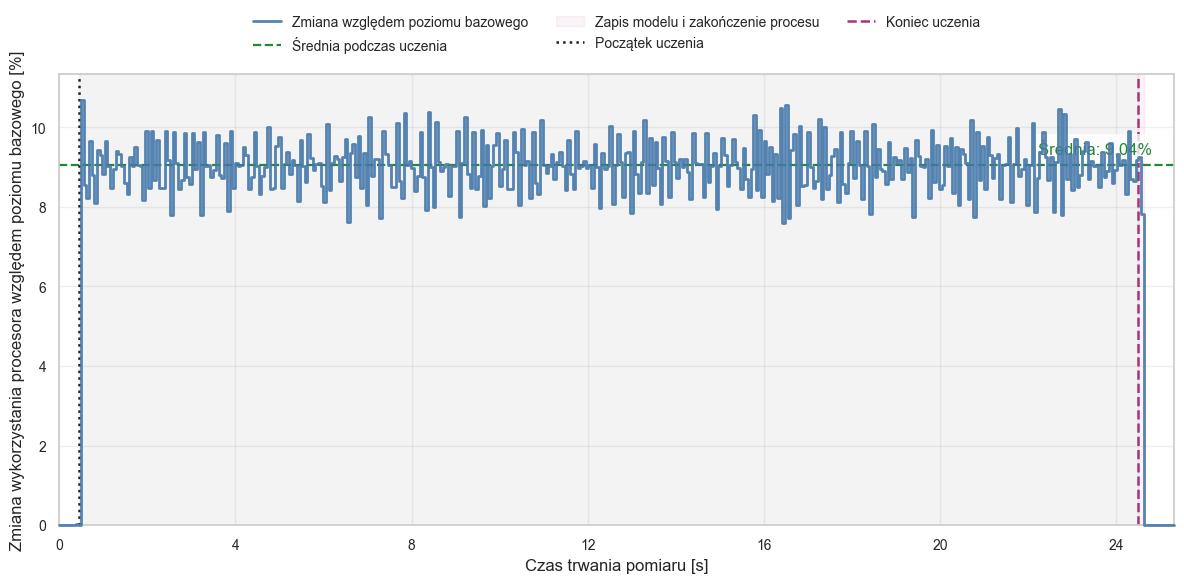

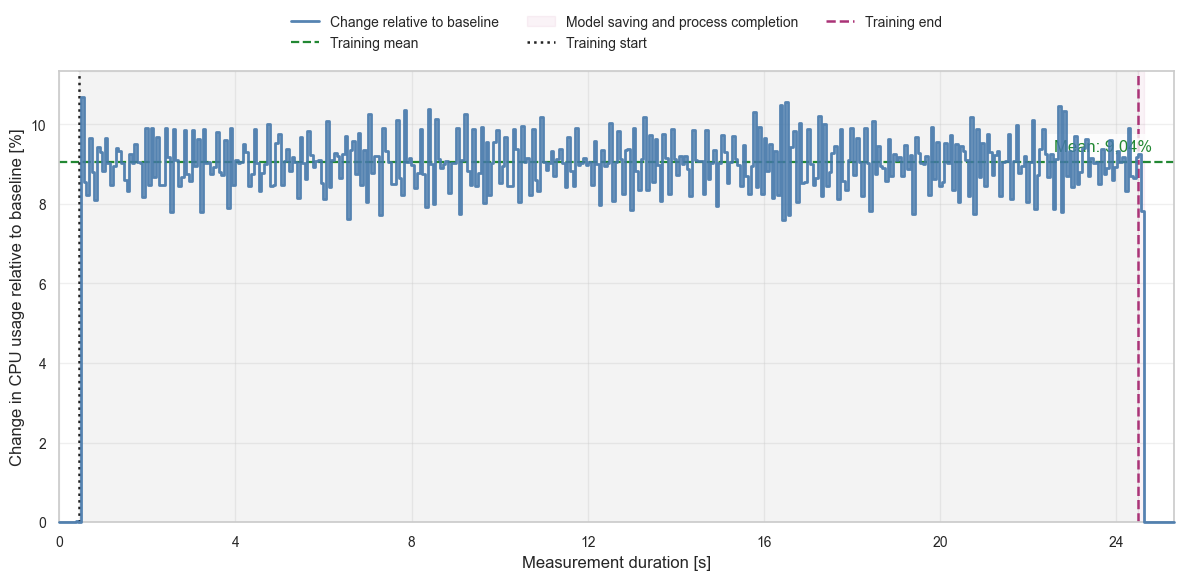

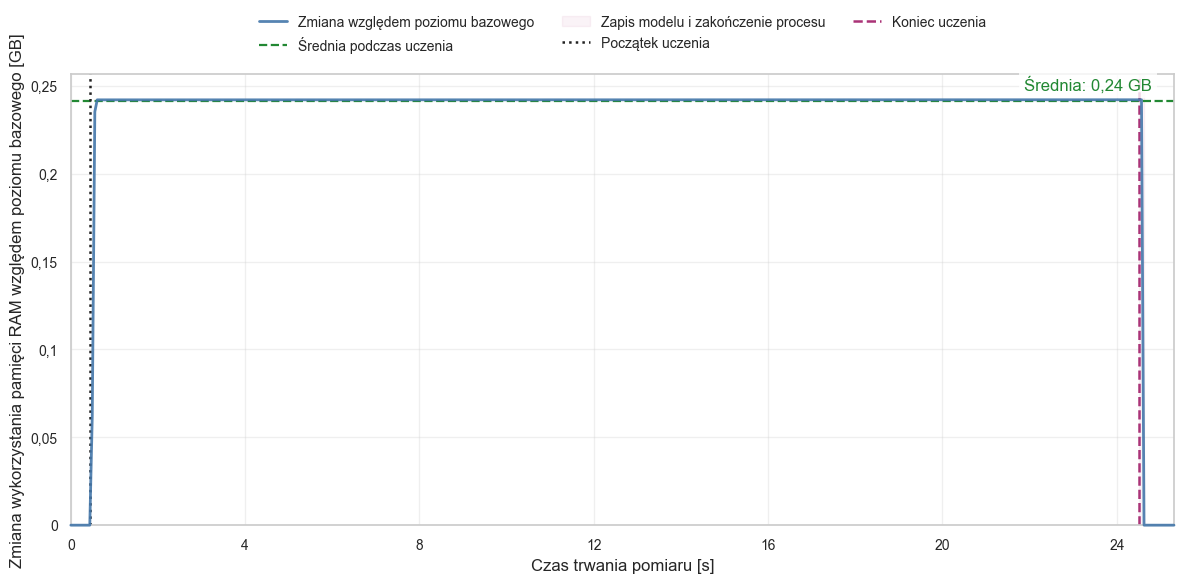

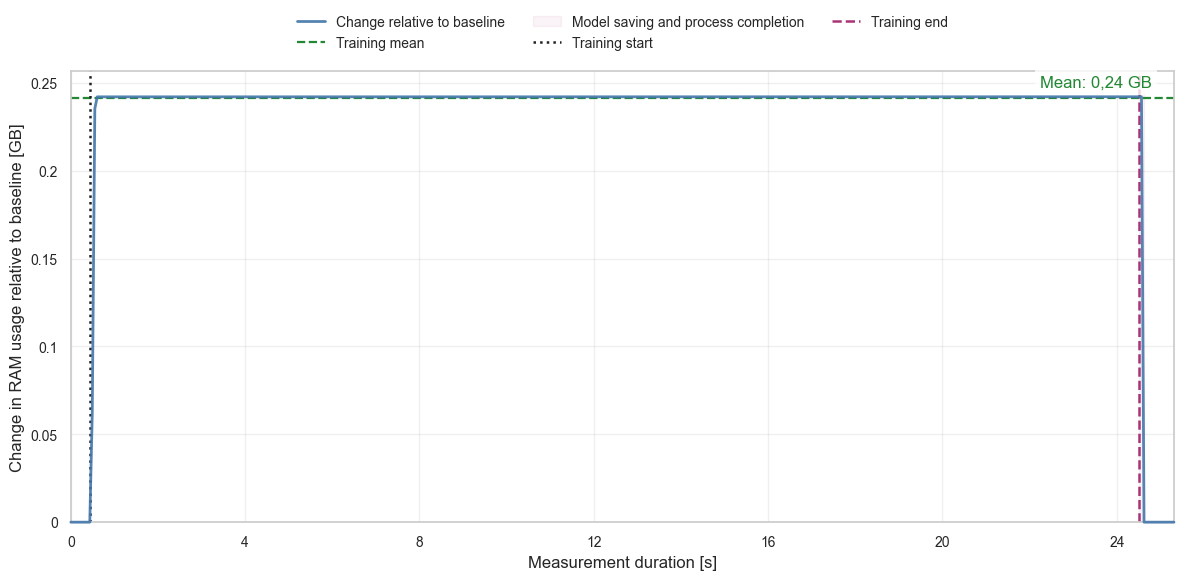

Zapisano ślad: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/url_corpus/resource_usage/logistic_regression_full.csv
Zapisano wykres CPU: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/url_corpus/plots/logistic_regression/full/pl/logistic_regression_resource_usage_cpu.png
Zapisano wykres RAM: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/url_corpus/plots/logistic_regression/full/pl/logistic_regression_resource_usage_ram.png


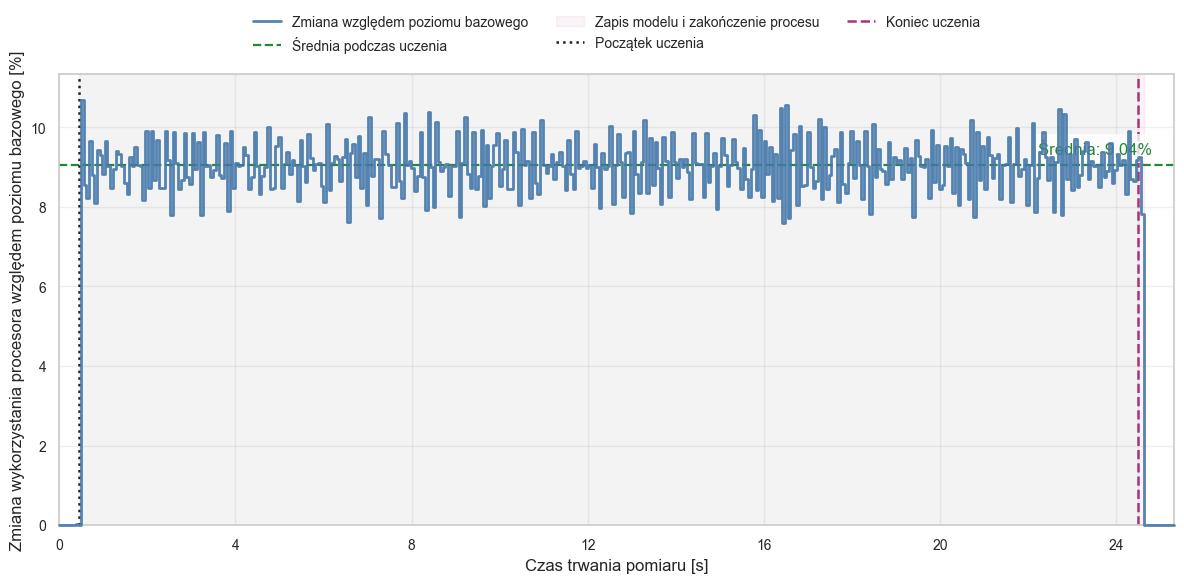

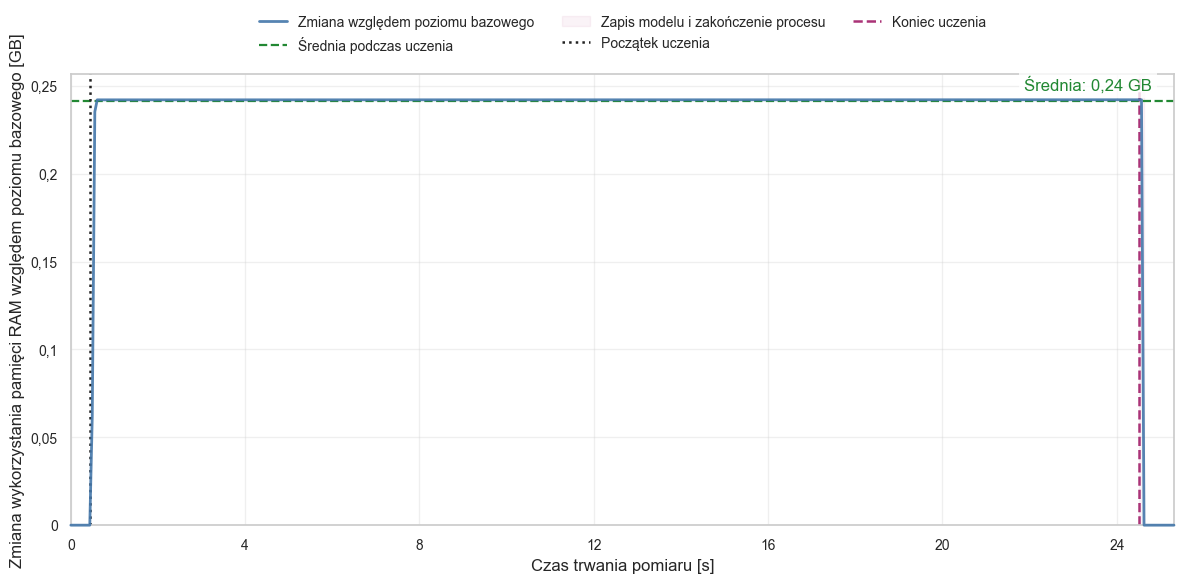

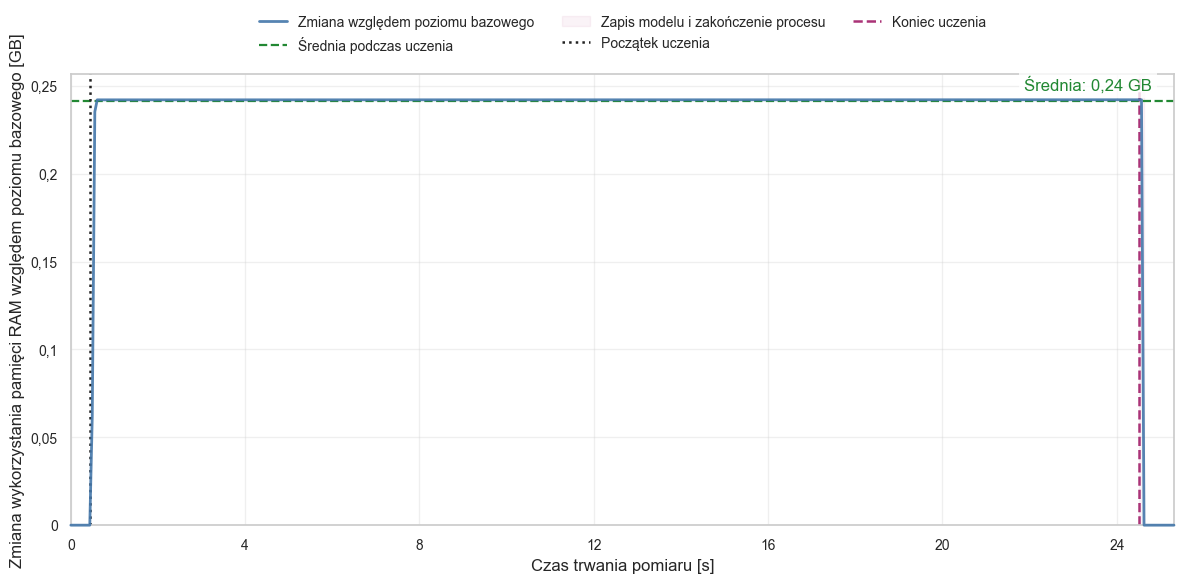

Poziom bazowy to mediana 8 próbek procesu izolowanego i jego procesów potomnych, zebranych bezpośrednio przed uczeniem (CPU: 0,04% łącznej mocy 11 rdzeni logicznych; RAM: 0,20 GB). Wykres przedstawia nieujemną różnicę: pomiar minus poziom bazowy.


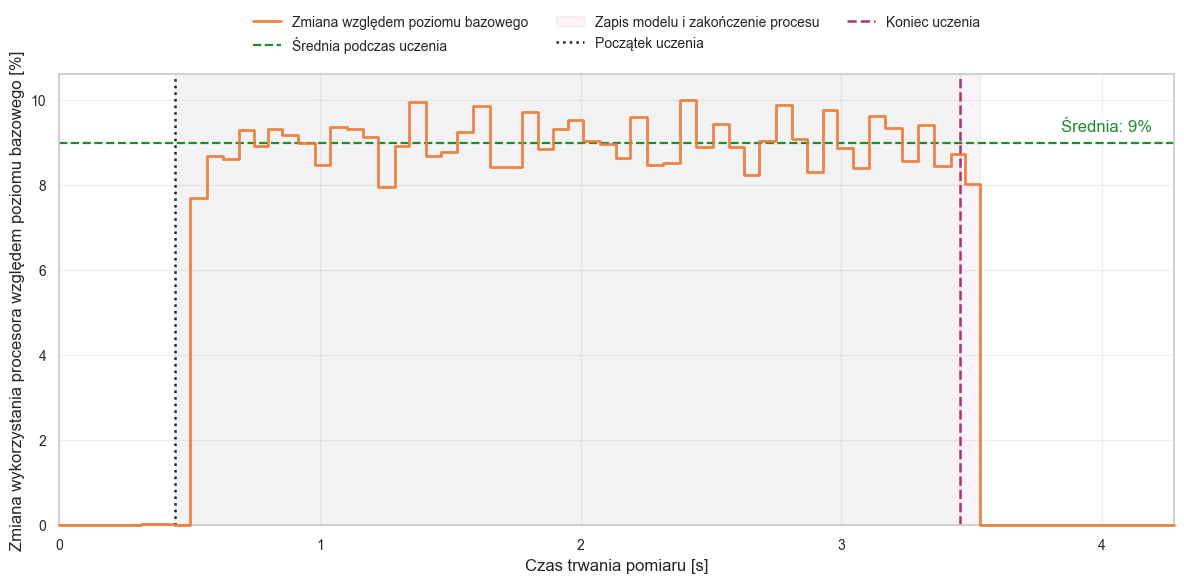

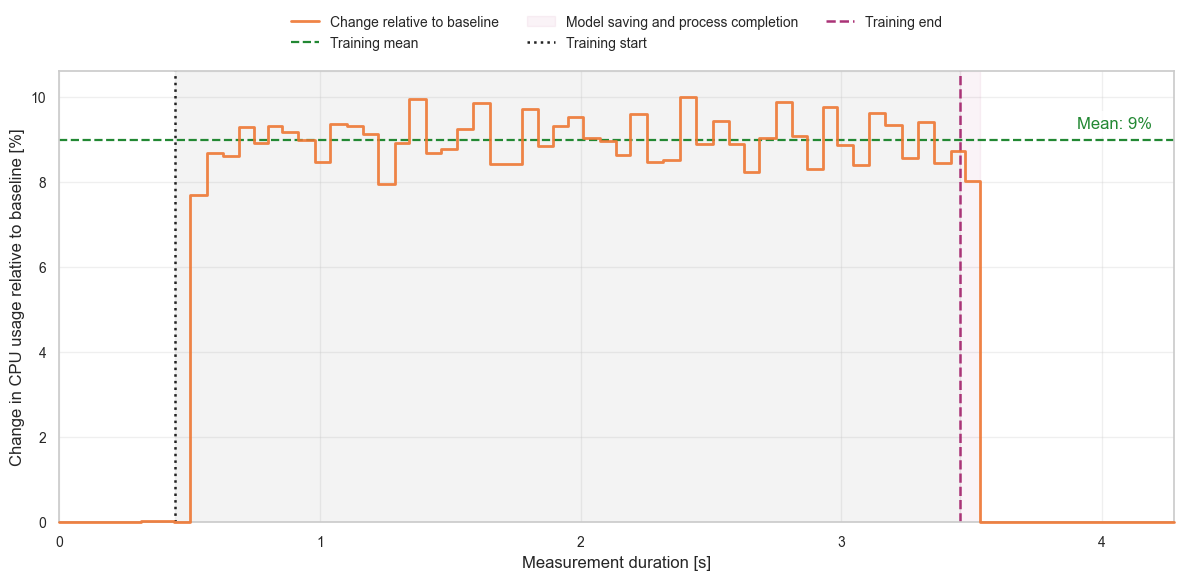

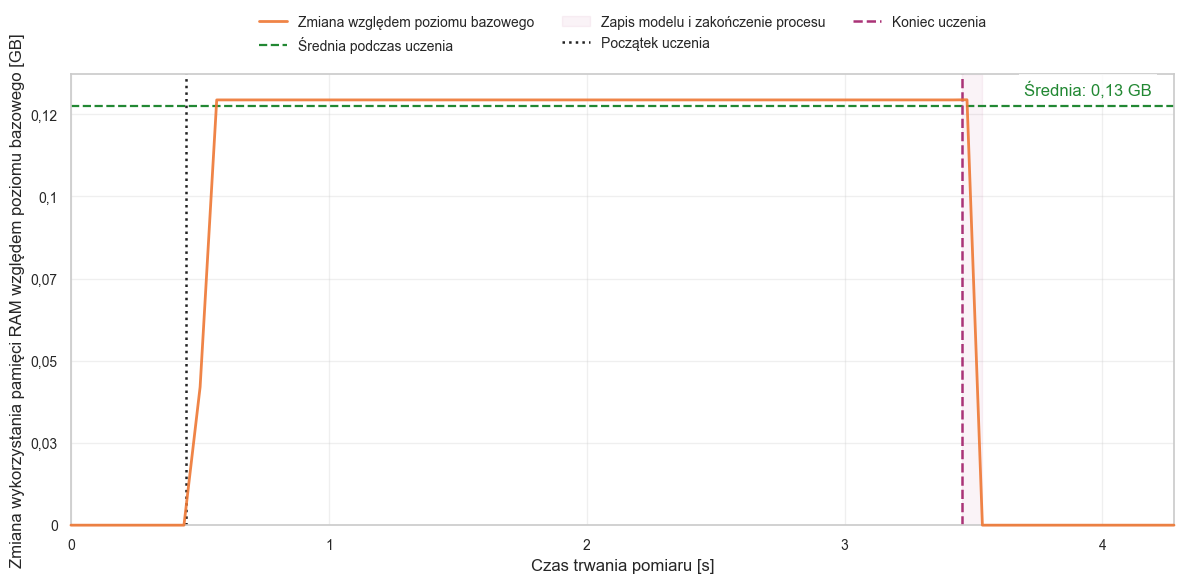

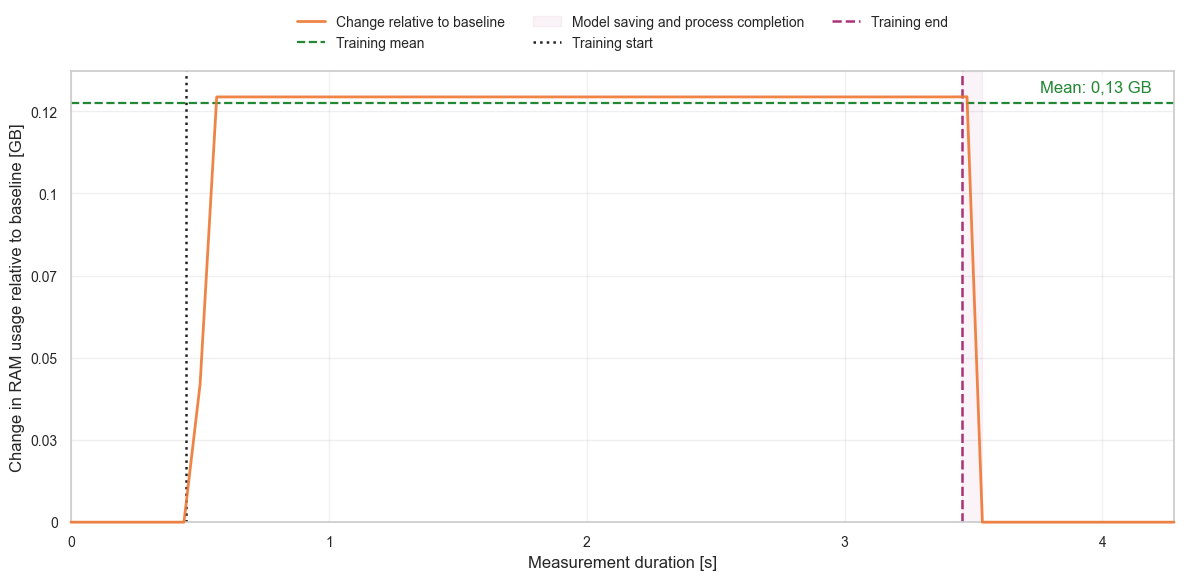

Zapisano ślad: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/url_corpus/resource_usage/logistic_regression_optimized.csv
Zapisano wykres CPU: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/url_corpus/plots/logistic_regression/optimized/pl/logistic_regression_resource_usage_cpu.png
Zapisano wykres RAM: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/url_corpus/plots/logistic_regression/optimized/pl/logistic_regression_resource_usage_ram.png


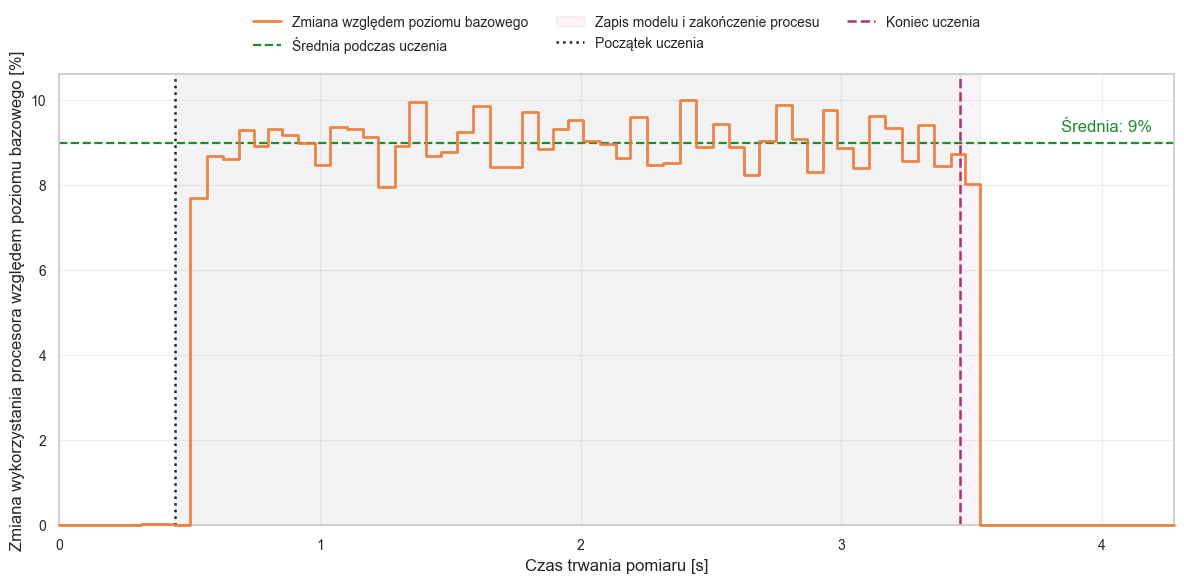

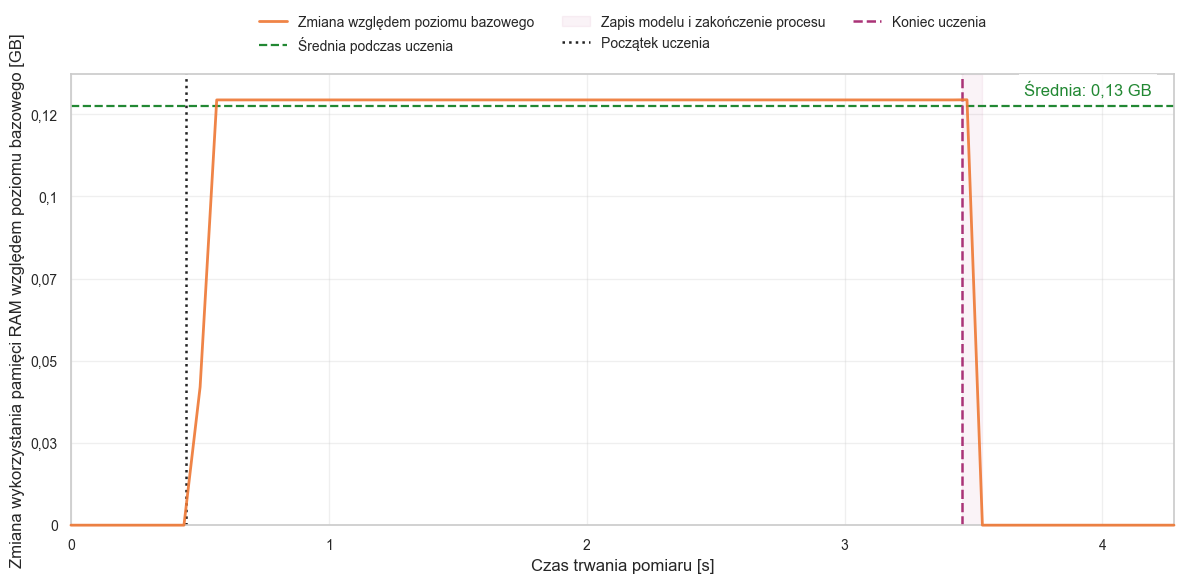

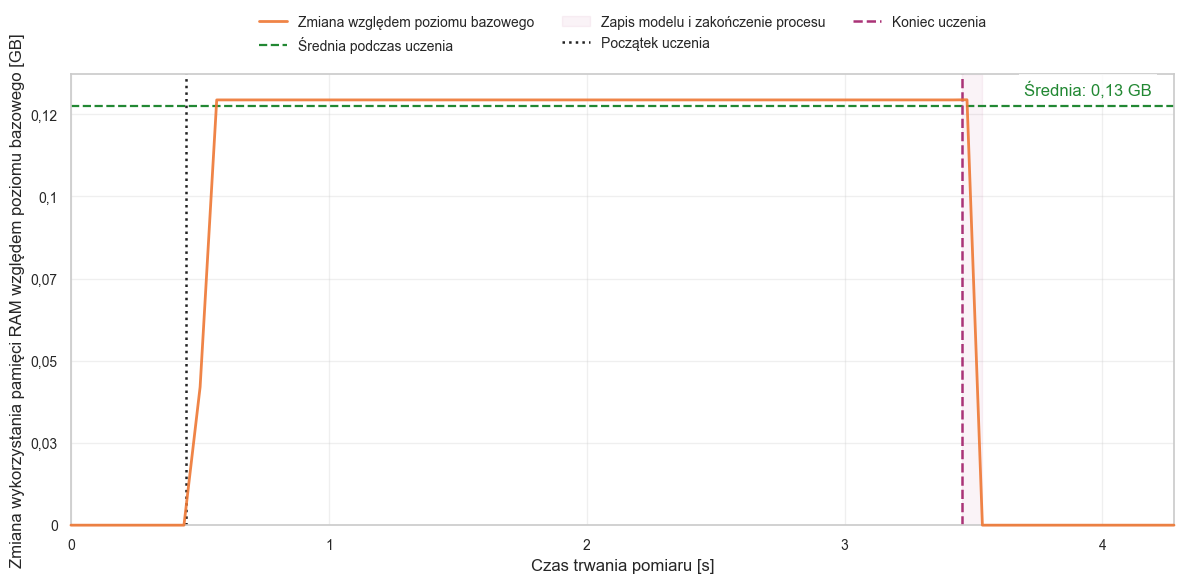

In [7]:
from IPython.display import display

for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    monitor = resource_stats[dataset_name]['monitor']
    stats = resource_stats[dataset_name]['stats']
    print(resource_baseline_summary(monitor))
    trace_dir = backend_root.parent / 'results' / 'url_corpus' / 'resource_usage'
    trace_dir.mkdir(parents=True, exist_ok=True)
    trace_path = trace_dir / f'logistic_regression_{dataset_key(dataset_name)}.csv'
    monitor.save_phase_trace(trace_path)
    cpu_figure, ram_figure = plot_resource_usage_separate(monitor, stats, dataset_name, include_post_training=True)
    cpu_path = save_dataset_figure(cpu_figure, PLOTS_DIR, dataset_name, 'logistic_regression_resource_usage_cpu.png')
    ram_path = save_dataset_figure(ram_figure, PLOTS_DIR, dataset_name, 'logistic_regression_resource_usage_ram.png')
    print(f'Zapisano ślad: {trace_path}')
    print(f'Zapisano wykres CPU: {cpu_path}')
    print(f'Zapisano wykres RAM: {ram_path}')
    display(cpu_figure)
    display(ram_figure)
    plt.close(cpu_figure)
    plt.close(ram_figure)
    plt.show()


## 6. Porównanie wyników uczenia i testowania

Miary dla procesu uczenia obliczane są na zbiorze uczącym, a miary testowe na
niezależnym zbiorze testowym. Każda miara jest prezentowana na osobnym wykresie
i wykorzystuje wyniki uzyskane przez wytrenowany model, bez jego ponownego
uczenia na potrzeby wizualizacji.

Walidacja oznacza ocenę modelu na danych, które nie uczestniczyły w jego
dopasowaniu w danym przebiegu, ale nadal należą do części danych przeznaczonej
do opracowania modelu. Nie jest ona testem końcowym. Dla każdego rozmiaru
podzbioru uczącego linia uczenia i linia walidacji przedstawiają średnią z pięciu
przebiegów, a półprzezroczyste pasmo przedstawia jedno odchylenie standardowe.
Niezależny zbiór testowy nie uczestniczy w wyznaczaniu tych krzywych.
Oś pozioma nie przedstawia liczby próbek walidacyjnych ani testowych.



EWALUACJA MODELU - PEŁNY ZBIÓR



WYNIKI NA ZBIORZE TESTOWYM:
  • Dokładność (Accuracy): 0.8507
  • Precyzja: 0.9352
  • Czułość: 0.7535
  • Współczynnik fałszywie dodatnich (FPR): 0.0522 (5.22%)
  • Próg skalibrowany na walidacji: 0.7648
  • Walidacyjny FPR przy wybranym progu: 4.53%
  • Walidacyjna czułość przy wybranym progu: 80.01%
  • Docelowy FPR kalibracji: 2.00%
  • Miara F1 (F1-Score): 0.8346
  • AUC-ROC: 0.9036
  • Błąd uczenia: 0.1294
  • Błąd testowania: 0.1493


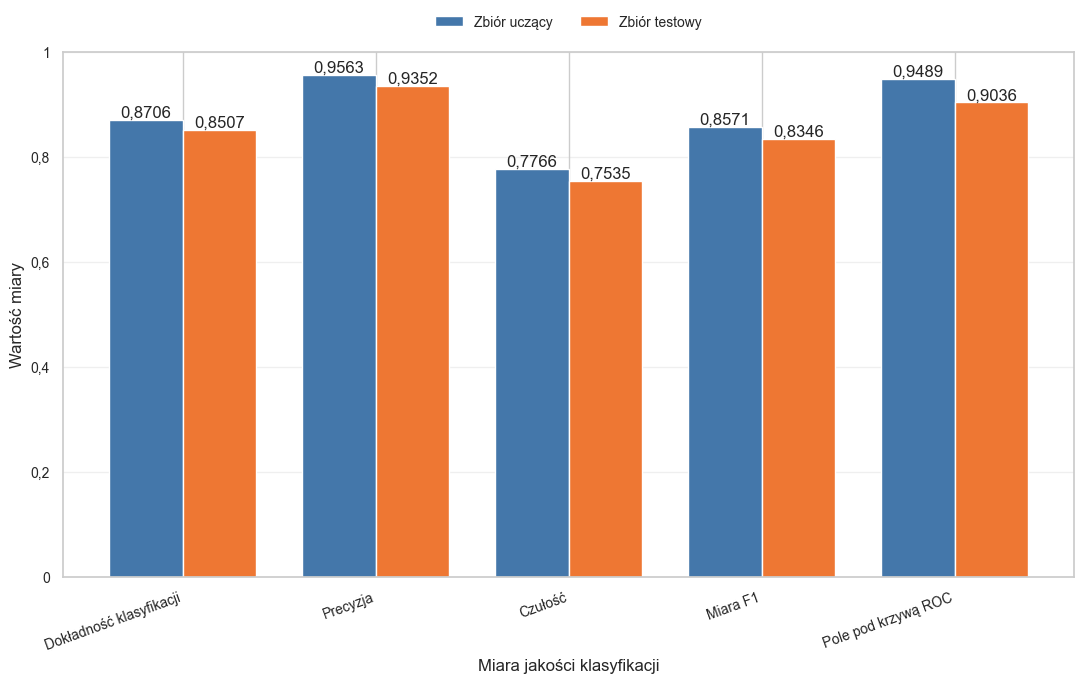

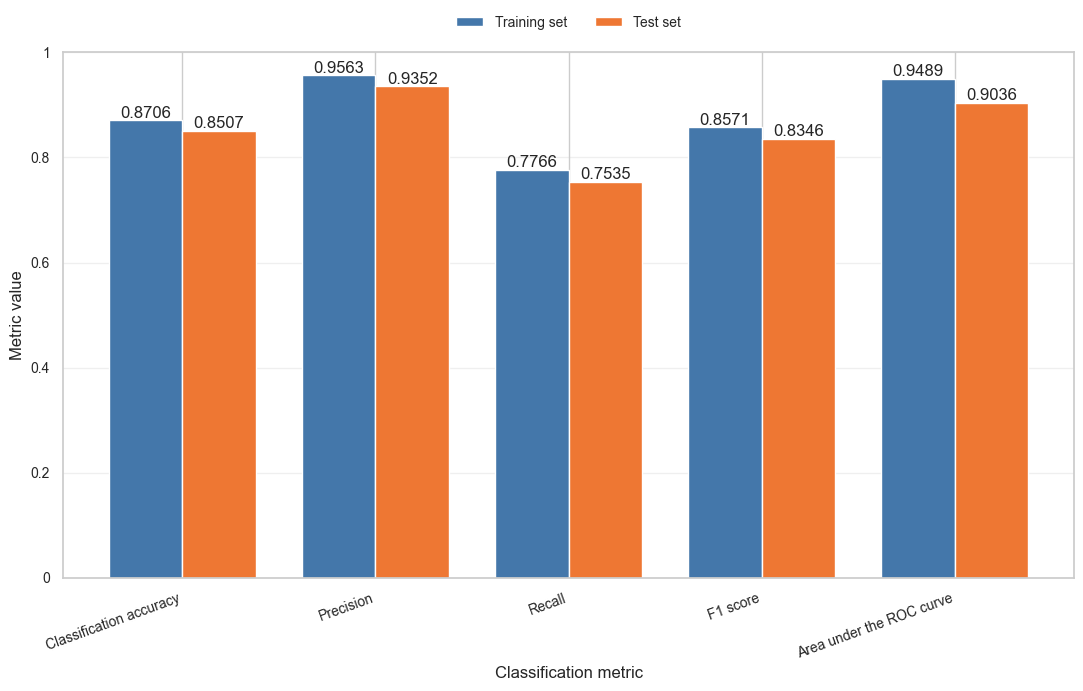

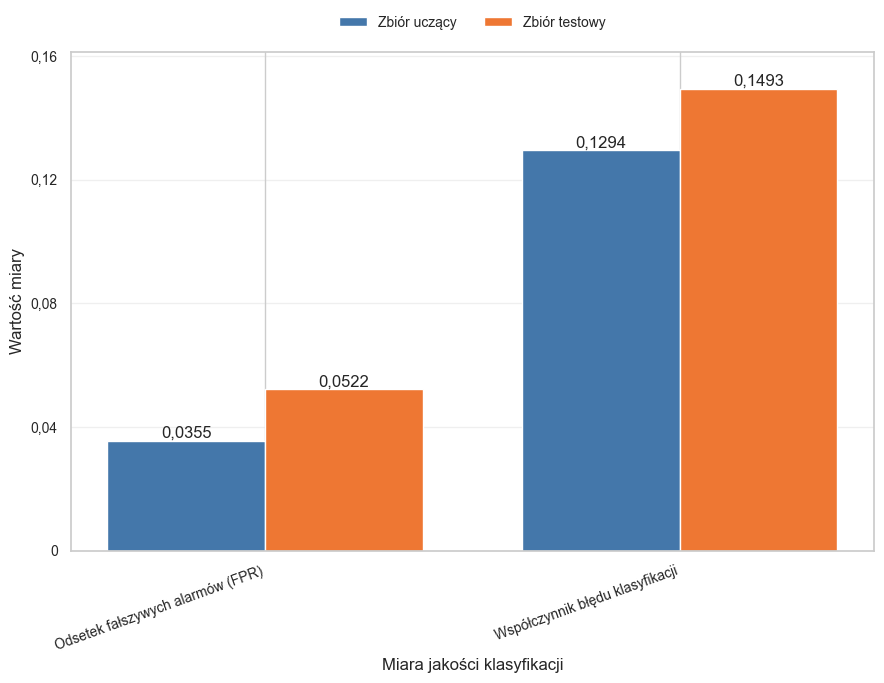

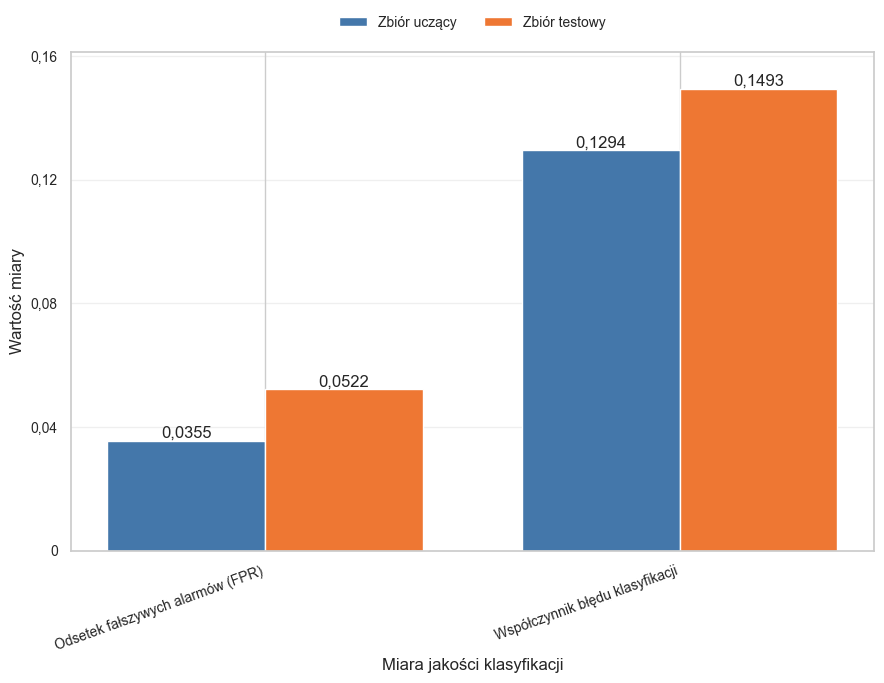

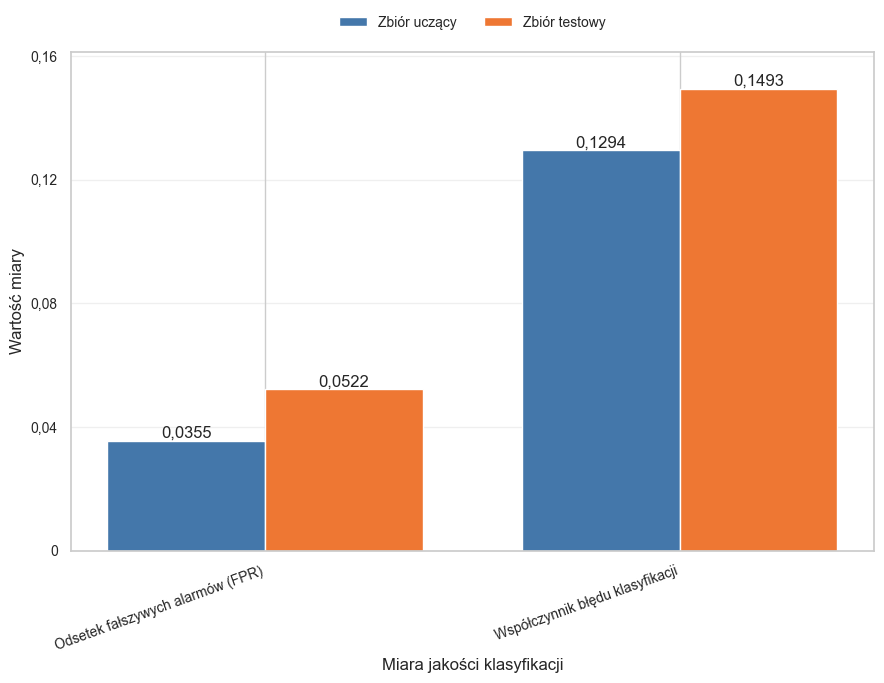

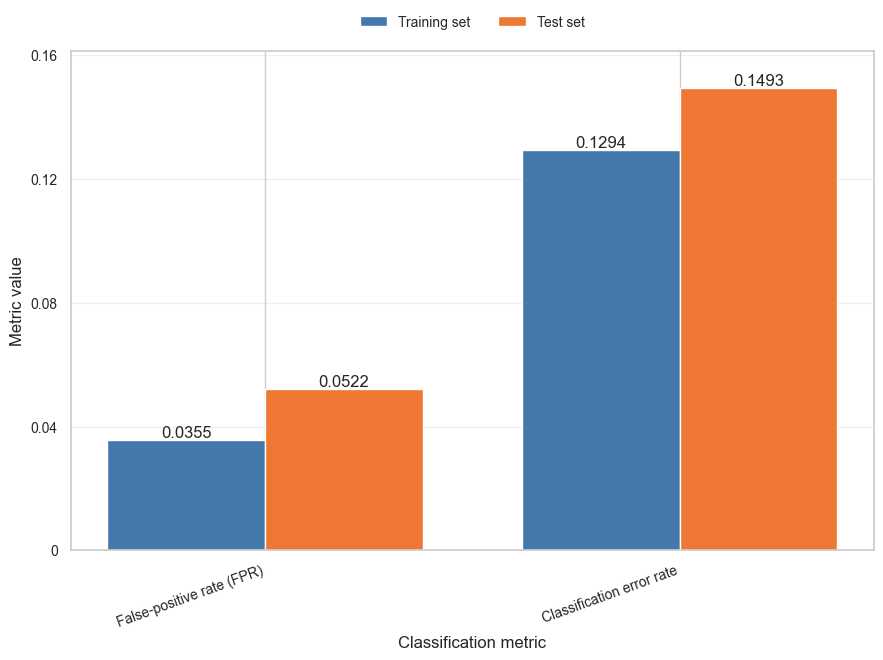


MACIERZ POMYŁEK:
  • Prawdziwie negatywne (TN): 9,952
  • Fałszywie pozytywne (FP): 548
  • Fałszywie negatywne (FN): 2,588
  • Prawdziwie pozytywne (TP): 7,912

PIĘCIOKROTNA WALIDACJA KRZYŻOWA:
  • Średni wynik ROC-AUC: 0.9486 ± 0.0009
  • Min: 0.9475
  • Max: 0.9500

EWALUACJA MODELU - ZOPTYMALIZOWANY ZBIÓR



WYNIKI NA ZBIORZE TESTOWYM:
  • Dokładność (Accuracy): 0.8499
  • Precyzja: 0.9338
  • Czułość: 0.7531
  • Współczynnik fałszywie dodatnich (FPR): 0.0534 (5.34%)
  • Próg skalibrowany na walidacji: 0.7627
  • Walidacyjny FPR przy wybranym progu: 4.75%
  • Walidacyjna czułość przy wybranym progu: 80.01%
  • Docelowy FPR kalibracji: 2.00%
  • Miara F1 (F1-Score): 0.8338
  • AUC-ROC: 0.8986
  • Błąd uczenia: 0.1290
  • Błąd testowania: 0.1501


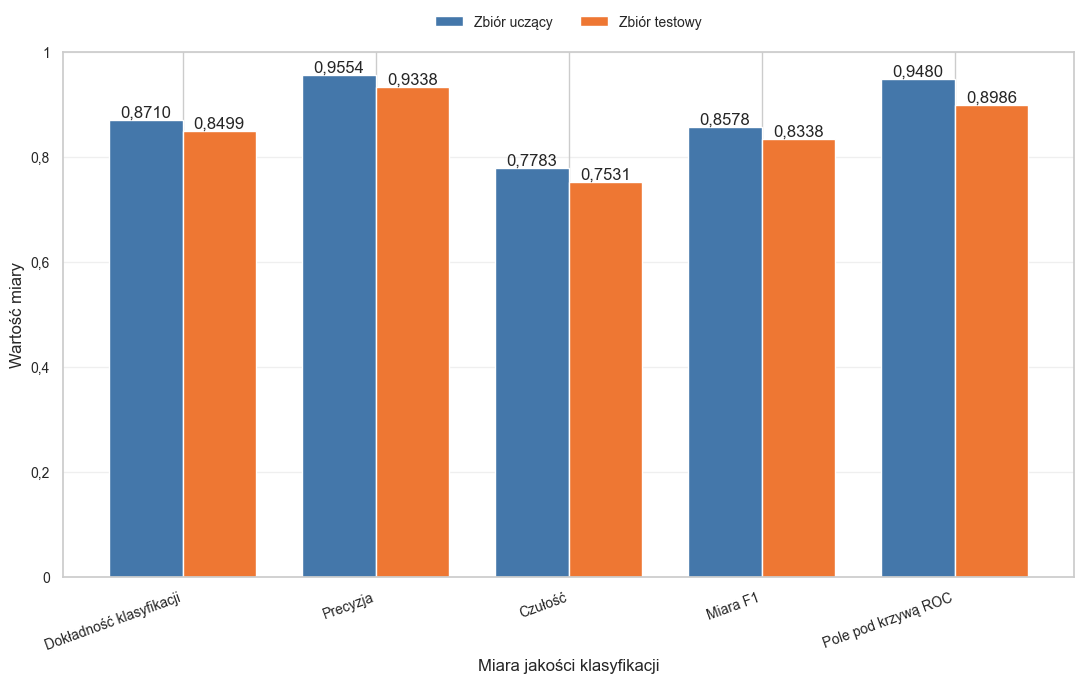

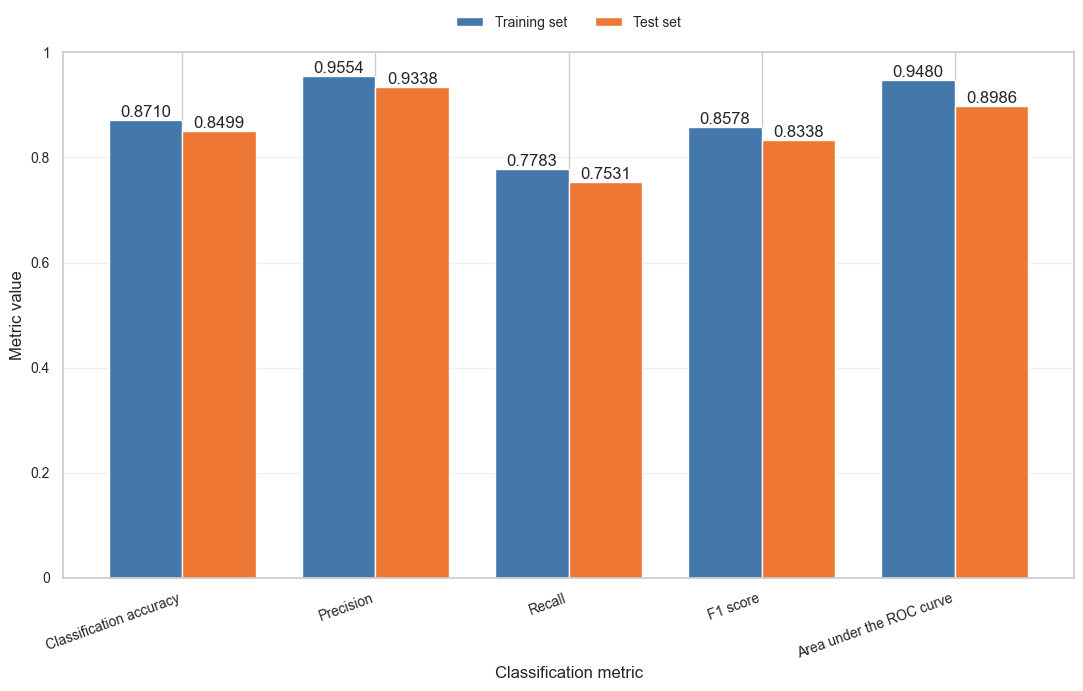

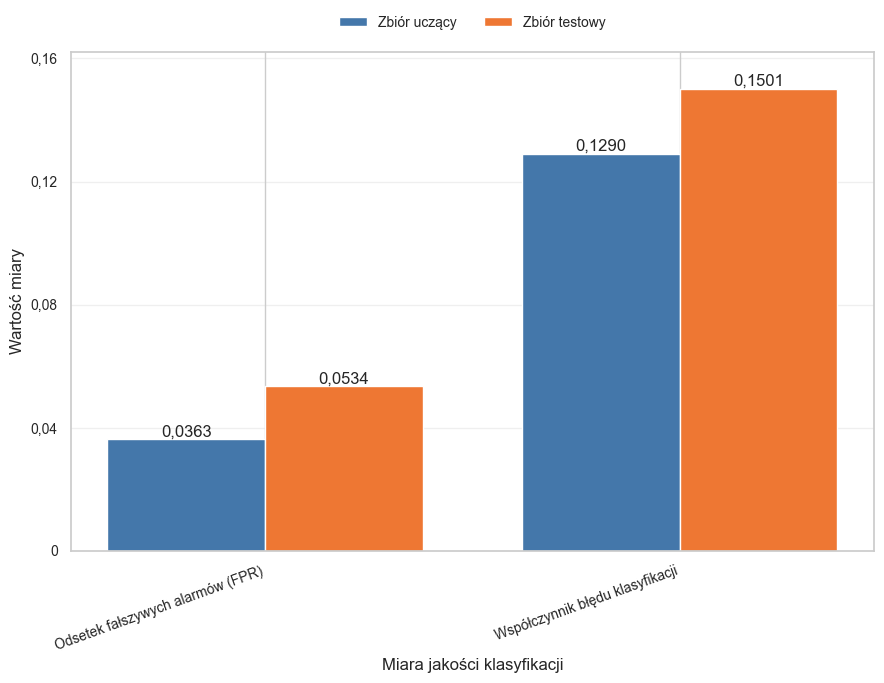

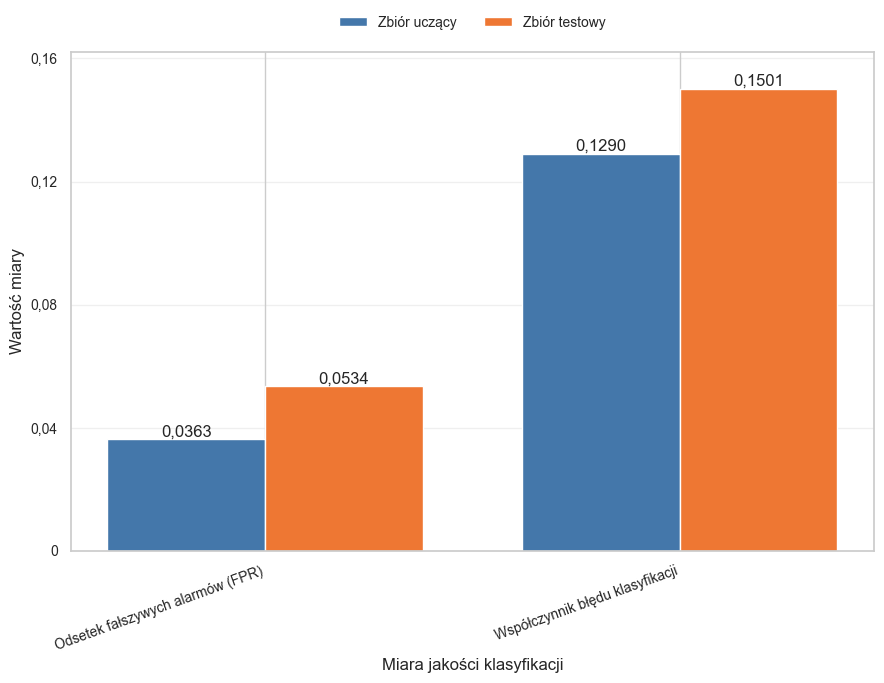

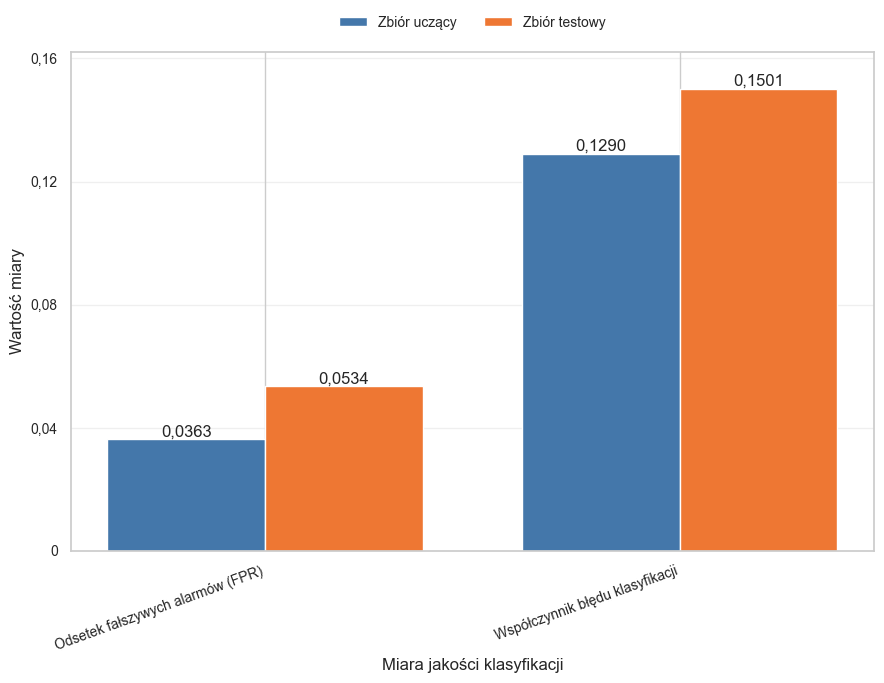

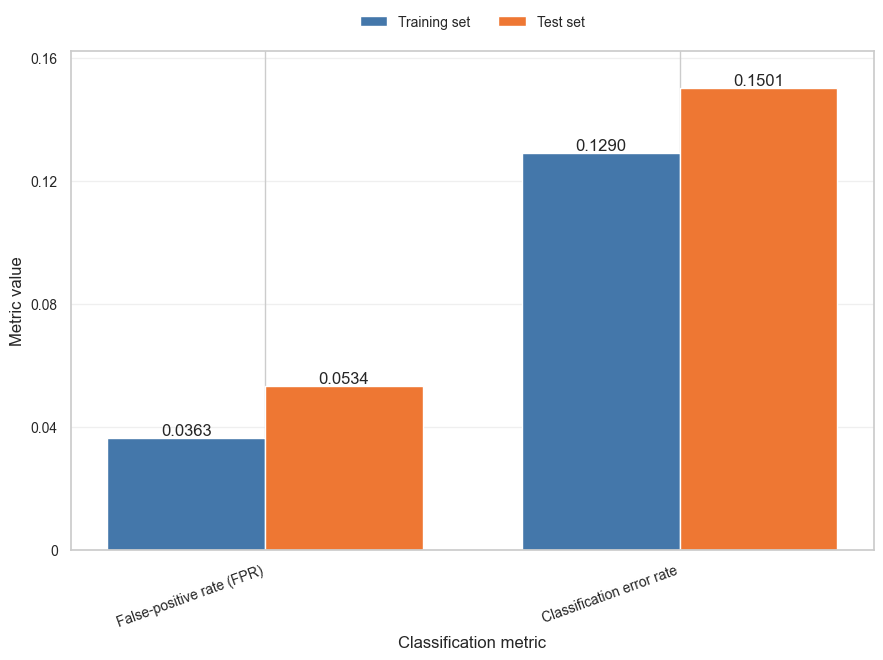


MACIERZ POMYŁEK:
  • Prawdziwie negatywne (TN): 9,939
  • Fałszywie pozytywne (FP): 561
  • Fałszywie negatywne (FN): 2,592
  • Prawdziwie pozytywne (TP): 7,908

PIĘCIOKROTNA WALIDACJA KRZYŻOWA:
  • Średni wynik ROC-AUC: 0.9478 ± 0.0009
  • Min: 0.9468
  • Max: 0.9493

PORÓWNANIE WYNIKÓW
Metryka                  Pełny zbiór Zoptymalizowany zbiór
--------------------------------------------------------------------------------
Accuracy                      0.8507          0.8499 (-0.0008)
Precision                     0.9352          0.9338 (-0.0015)
Recall                        0.7535          0.7531 (-0.0004)
False_positive_rate           0.0522          0.0534 (+0.0012)
F1                            0.8346          0.8338 (-0.0008)
Auc_roc                       0.9036          0.8986 (-0.0050)


In [8]:
evaluation_results = {}

for dataset_name, model_data in trained_models.items():
    print(f"\n{'='*80}")
    print(f"EWALUACJA MODELU - {dataset_name.upper()}")
    print(f"{'='*80}")

    model = model_data['model']
    data = train_test_data[dataset_name]

    X_test_scaled = data['X_test_scaled']
    y_test = data['y_test']
    X_train_scaled = data['X_train_scaled']
    y_train = data['y_train']

    y_val_proba = model.predict_proba(data['X_val_scaled'])[:, 1]
    threshold_info = calibrate_threshold(
        data['y_val'], y_val_proba,
        max_false_positive_rate=DEFAULT_MAX_FALSE_POSITIVE_RATE,
        min_recall=DEFAULT_MIN_RECALL,
    )
    decision_threshold = threshold_info['threshold']
    y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]
    y_pred = (y_pred_proba >= decision_threshold).astype(int)
    y_train_proba = model.predict_proba(X_train_scaled)[:, 1]
    y_train_pred = (y_train_proba >= decision_threshold).astype(int)

    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    false_positive_rate = fp / (fp + tn) if (fp + tn) else 0.0

    train_cm = confusion_matrix(y_train, y_train_pred)
    train_tn, train_fp, train_fn, train_tp = train_cm.ravel()
    train_false_positive_rate = train_fp / (train_fp + train_tn) if (train_fp + train_tn) else 0.0
    train_accuracy = accuracy_score(y_train, y_train_pred)
    train_precision = precision_score(y_train, y_train_pred)
    train_recall = recall_score(y_train, y_train_pred)
    train_f1 = f1_score(y_train, y_train_pred)
    accuracy = accuracy_score(y_test, y_pred)
    train_error_rate = 1.0 - accuracy_score(y_train, y_train_pred)
    test_error_rate = 1.0 - accuracy
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc_roc = roc_auc_score(y_test, y_pred_proba)
    train_auc_roc = roc_auc_score(y_train, y_train_proba)
    train_bce = log_loss(y_train, y_train_proba)
    test_bce = log_loss(y_test, y_pred_proba)

    cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring='roc_auc')

    evaluation_results[dataset_name] = {
        'y_pred': y_pred,
        'y_pred_proba': y_pred_proba,
        'confusion_matrix': cm,
        'train_accuracy': train_accuracy,
        'train_precision': train_precision,
        'train_recall': train_recall,
        'train_false_positive_rate': train_false_positive_rate,
        'train_f1': train_f1,
        'accuracy': accuracy,
        'train_error_rate': train_error_rate,
        'test_error_rate': test_error_rate,
        'precision': precision,
        'recall': recall,
        'false_positive_rate': false_positive_rate,
        'decision_threshold': decision_threshold,
        'threshold_calibration': threshold_info,
        'f1': f1,
        'auc_roc': auc_roc,
        'train_auc_roc': train_auc_roc,
        'train_bce': train_bce,
        'test_bce': test_bce,
        'cv_scores': cv_scores,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std()
    }

    print(f"\nWYNIKI NA ZBIORZE TESTOWYM:")
    print(f"  • Dokładność (Accuracy): {accuracy:.4f}")
    print(f"  • Precyzja: {precision:.4f}")
    print(f"  • Czułość: {recall:.4f}")
    print(f"  • Współczynnik fałszywie dodatnich (FPR): {false_positive_rate:.4f} ({false_positive_rate:.2%})")
    print(f"  • Próg skalibrowany na walidacji: {decision_threshold:.4f}")
    print(f"  • Walidacyjny FPR przy wybranym progu: {threshold_info['validation_fpr']:.2%}")
    print(f"  • Walidacyjna czułość przy wybranym progu: {threshold_info['validation_recall']:.2%}")
    print(f"  • Docelowy FPR kalibracji: {threshold_info['target_fpr']:.2%}")
    print(f"  • Miara F1 (F1-Score): {f1:.4f}")
    print(f"  • AUC-ROC: {auc_roc:.4f}")
    print(f"  • Błąd uczenia: {train_error_rate:.4f}")
    print(f"  • Błąd testowania: {test_error_rate:.4f}")

    remove_dataset_figure(
        PLOTS_DIR, dataset_name, 'logistic_regression_final_error_rate.png'
    )

    train_metrics, test_metrics = classification_metric_sets(
        evaluation_results[dataset_name]
    )
    metric_figures = plot_final_train_test_metric_groups(
        train_metrics, test_metrics
    )
    for group_name, metric_figure in metric_figures.items():
        save_dataset_figure(
            metric_figure, PLOTS_DIR, dataset_name,
            f'logistic_regression_metrics_{group_name}.png',
        )
        plt.show()

    print(f"\nMACIERZ POMYŁEK:")
    print(f"  • Prawdziwie negatywne (TN): {tn:,}")
    print(f"  • Fałszywie pozytywne (FP): {fp:,}")
    print(f"  • Fałszywie negatywne (FN): {fn:,}")
    print(f"  • Prawdziwie pozytywne (TP): {tp:,}")

    print(f"\nPIĘCIOKROTNA WALIDACJA KRZYŻOWA:")
    print(f"  • Średni wynik ROC-AUC: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
    print(f"  • Min: {cv_scores.min():.4f}")
    print(f"  • Max: {cv_scores.max():.4f}")

print(f"\n{'='*80}")
print("PORÓWNANIE WYNIKÓW")
print(f"{'='*80}")
print(f"{'Metryka':<20} {'Pełny zbiór':>15} {'Zoptymalizowany zbiór':>20}")
print(f"{'-'*80}")
for metric in ['accuracy', 'precision', 'recall', 'false_positive_rate', 'f1', 'auc_roc']:
    full_val = evaluation_results['Pełny zbiór'][metric]
    opt_val = evaluation_results['Zoptymalizowany zbiór'][metric]
    diff = opt_val - full_val
    diff_str = f"({diff:+.4f})" if diff != 0 else ""
    print(f"{metric.capitalize():<20} {full_val:>15.4f} {opt_val:>15.4f} {diff_str:>5}")

## 7. Wizualizacja kompleksowa i analiza


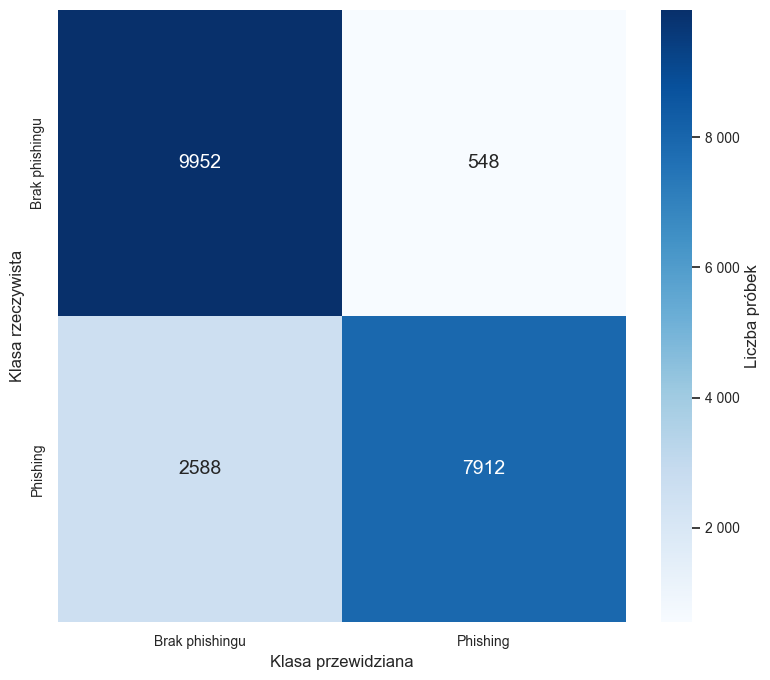

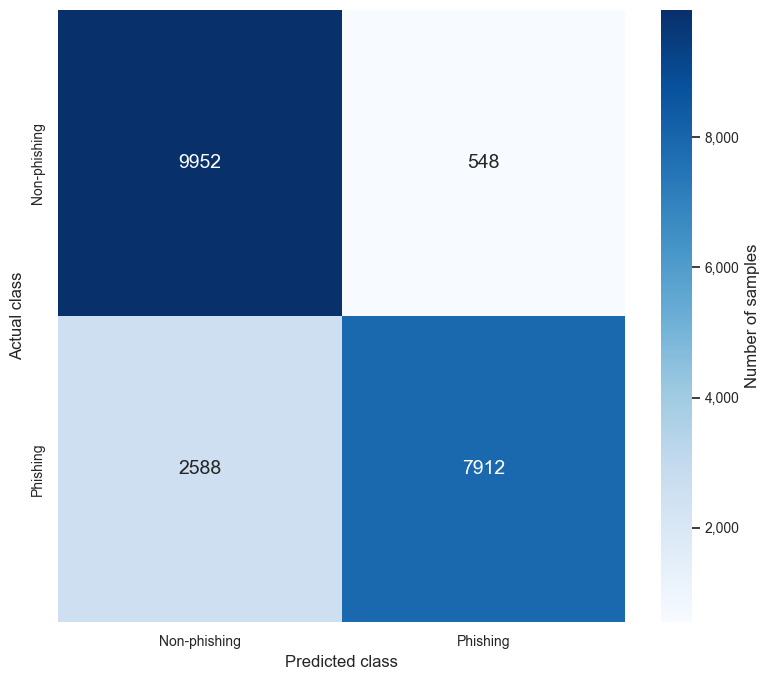

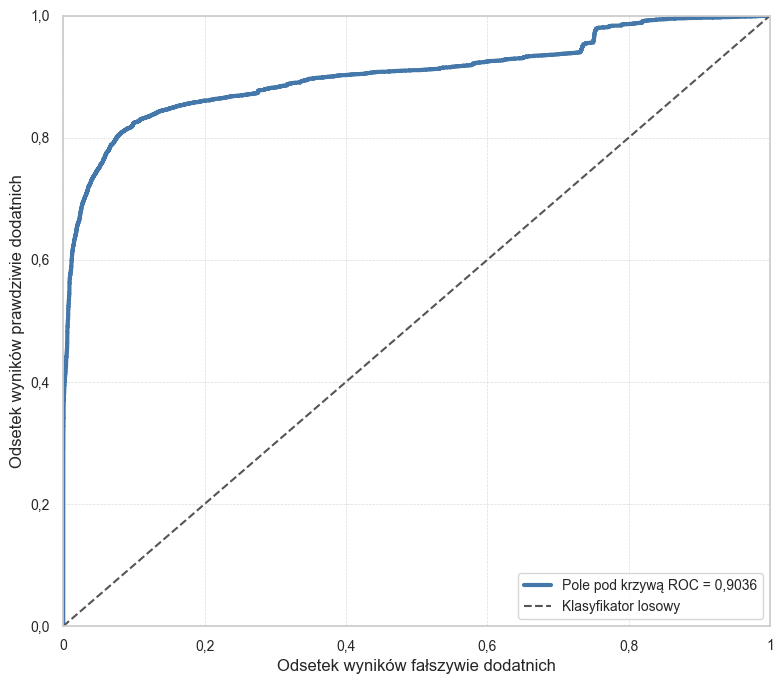

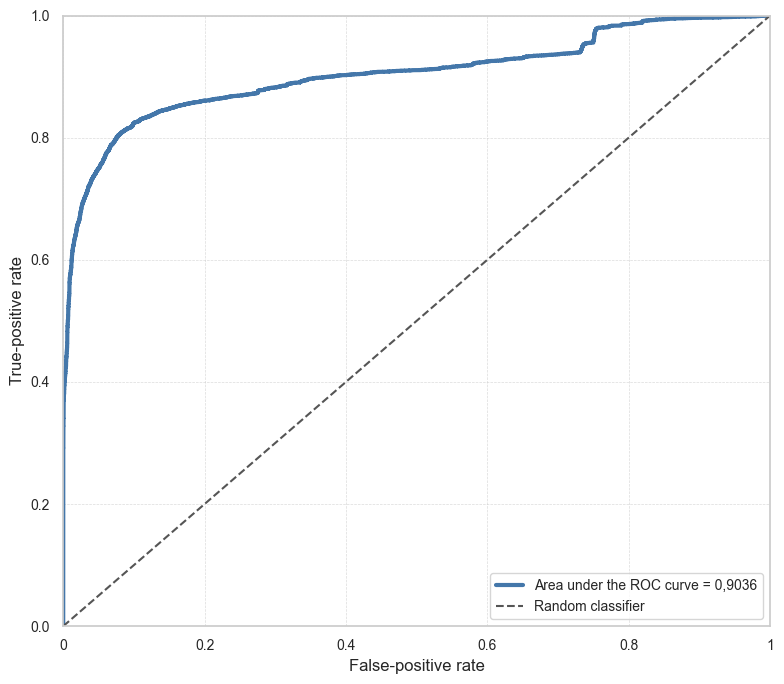

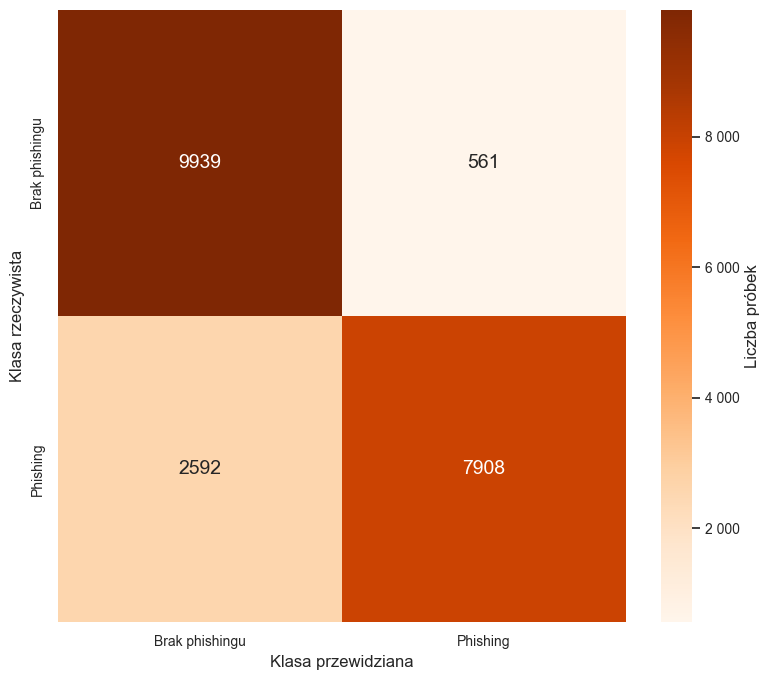

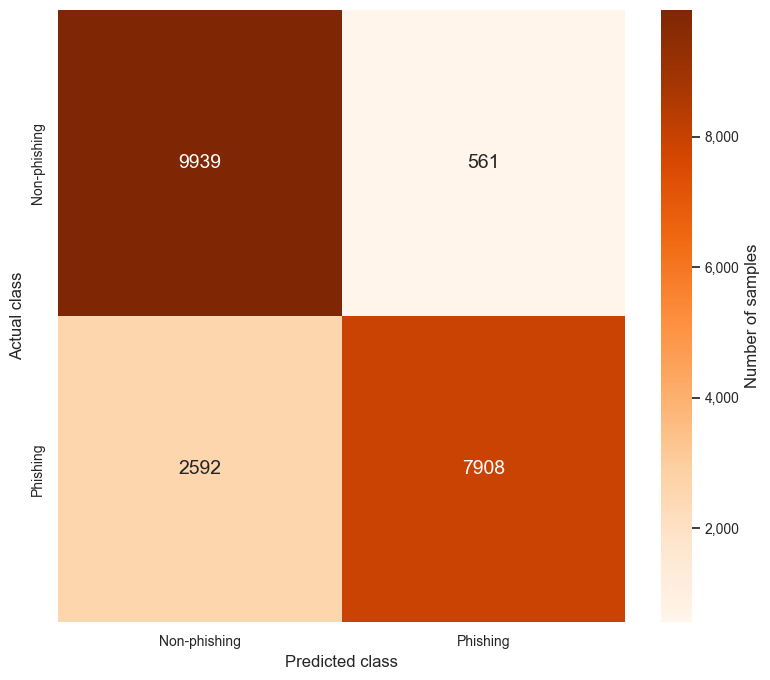

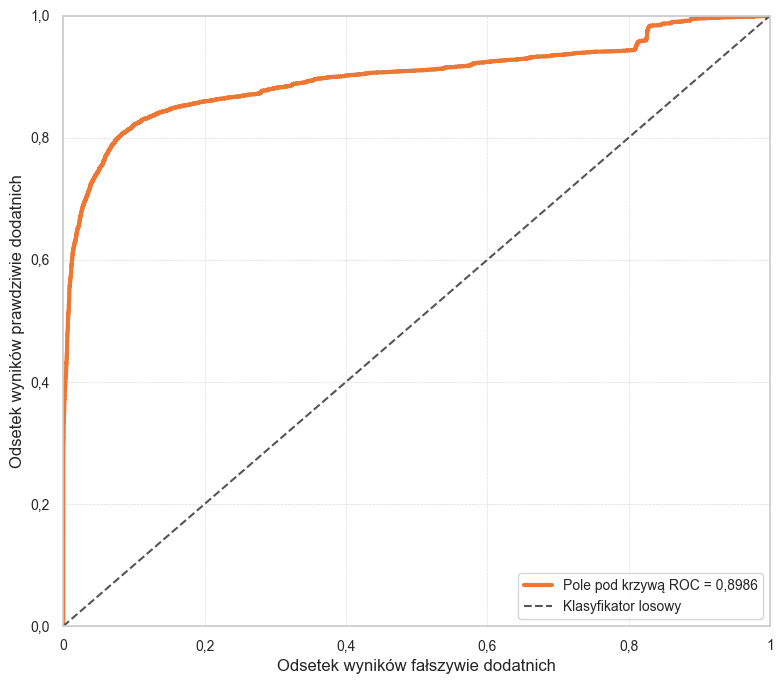

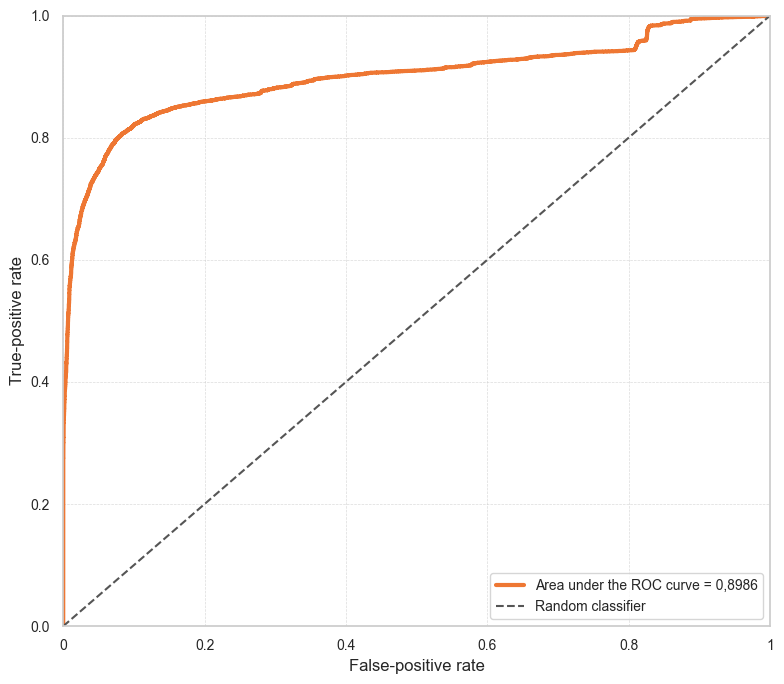

In [9]:
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    evaluation = evaluation_results[dataset_name]

    confusion_figure, _ = plot_confusion_matrix(
        evaluation['confusion_matrix'], dataset_name,
    )
    save_dataset_figure(
        confusion_figure, PLOTS_DIR, dataset_name, 'logistic_regression_confusion_matrix.png'
    )
    plt.show()

    roc_figure, _ = plot_roc_curve(
        train_test_data[dataset_name]['y_test'], evaluation['y_pred_proba'], evaluation['auc_roc'], dataset_name,
    )
    save_dataset_figure(
        roc_figure, PLOTS_DIR, dataset_name, 'logistic_regression_roc_curve.png'
    )
    plt.show()


## 7.1. Porównanie metryk w postaci wykresów słupkowych


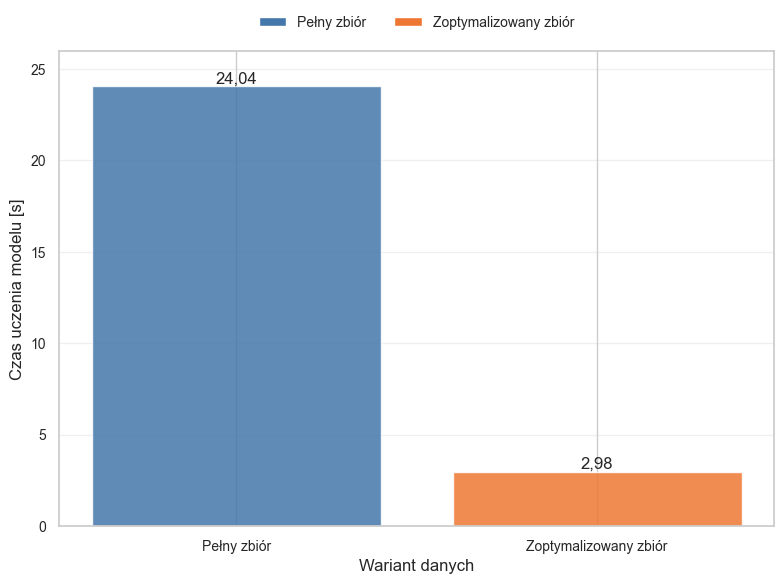

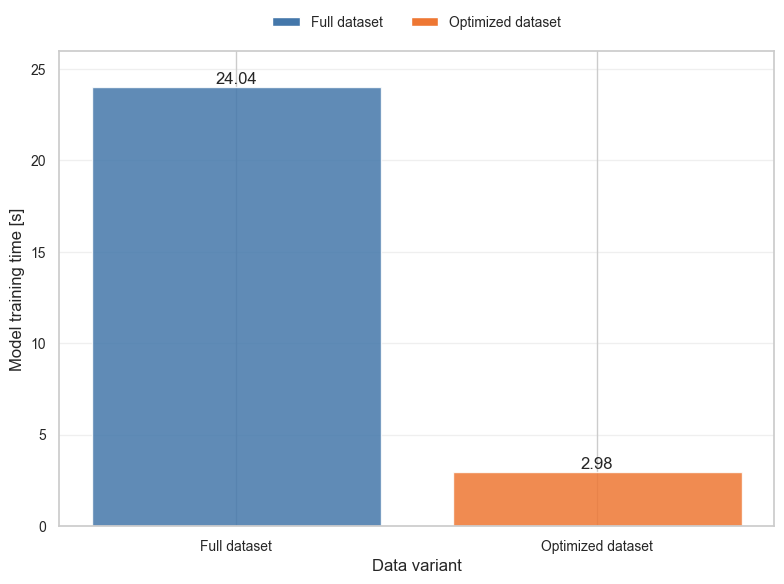

,Wariant danych,Liczba cech,Redukcja liczby cech,Redukcja [%]
0,Pełny zbiór,110,0,0.00
1,Zoptymalizowany zbiór,47,63,57.27


In [10]:
training_times = {}
feature_counts = {}
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    training_times[dataset_name] = float(trained_models[dataset_name]['training_time'])
    feature_counts[dataset_name] = int(data_splits[dataset_name]['feature_count'])
    remove_dataset_figure(
        PLOTS_DIR, dataset_name, 'logistic_regression_training_time.png'
    )
    remove_dataset_figure(
        PLOTS_DIR, dataset_name, 'logistic_regression_feature_count.png'
    )

time_figure, _ = plot_training_time_comparison(training_times)
save_comparison_figure(
    time_figure, PLOTS_DIR / 'logistic_regression_training_time_comparison.png'
)
plt.show()

feature_count_rows = feature_count_comparison_rows(
    feature_counts['Pełny zbiór'],
    feature_counts['Zoptymalizowany zbiór'],
)
display(pd.DataFrame(feature_count_rows))


## 7.1b. Ścieżka decyzyjna dla przykładowego URL


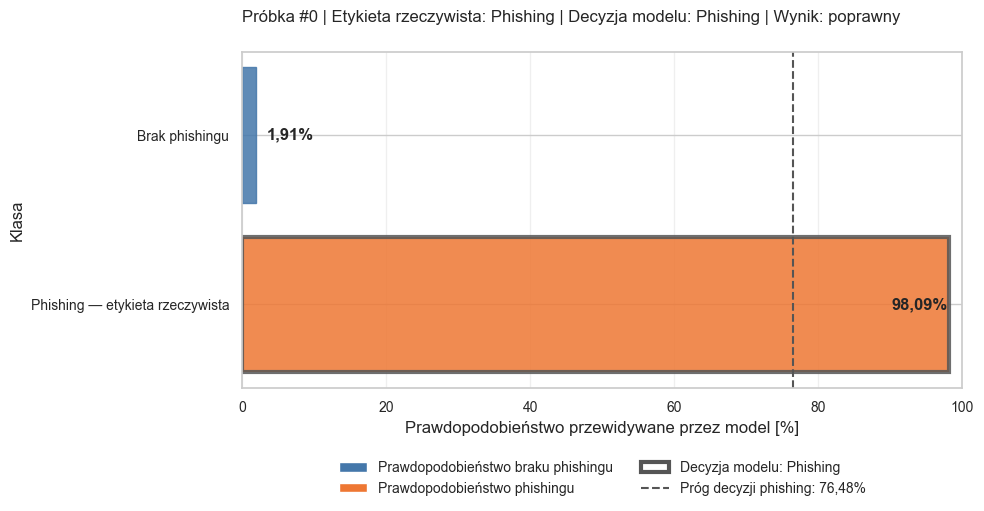

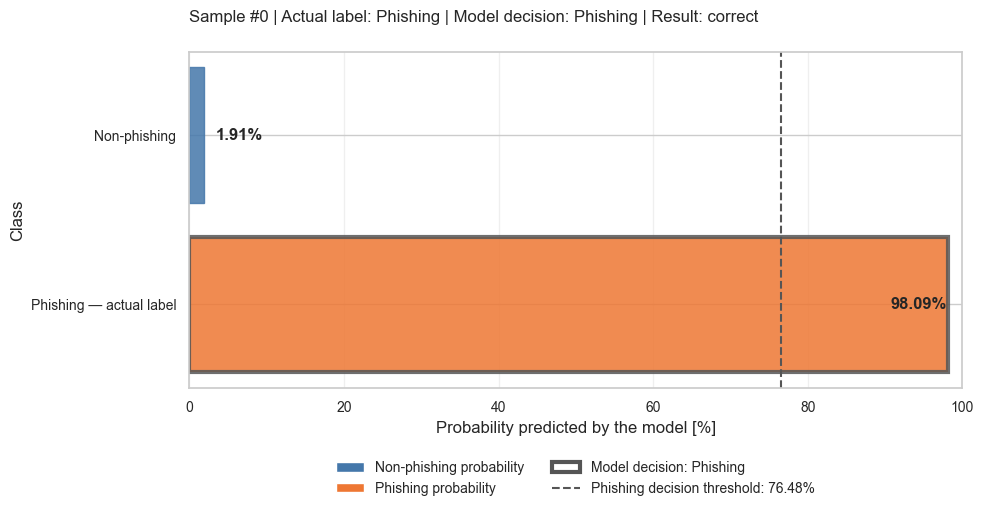

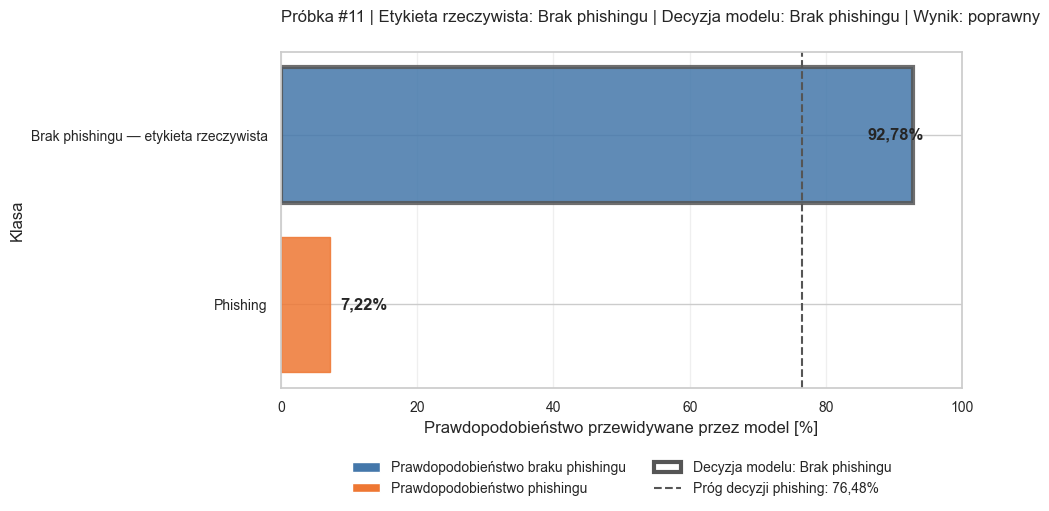

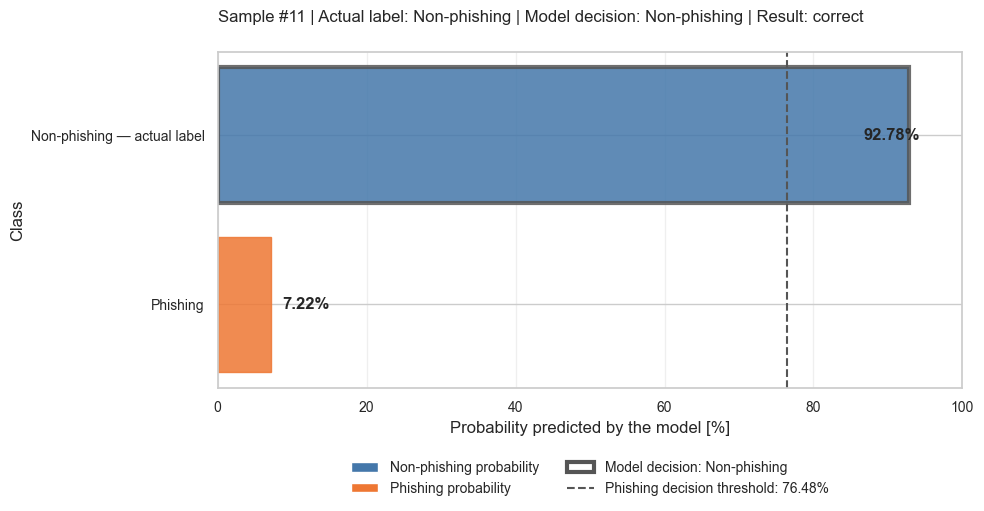

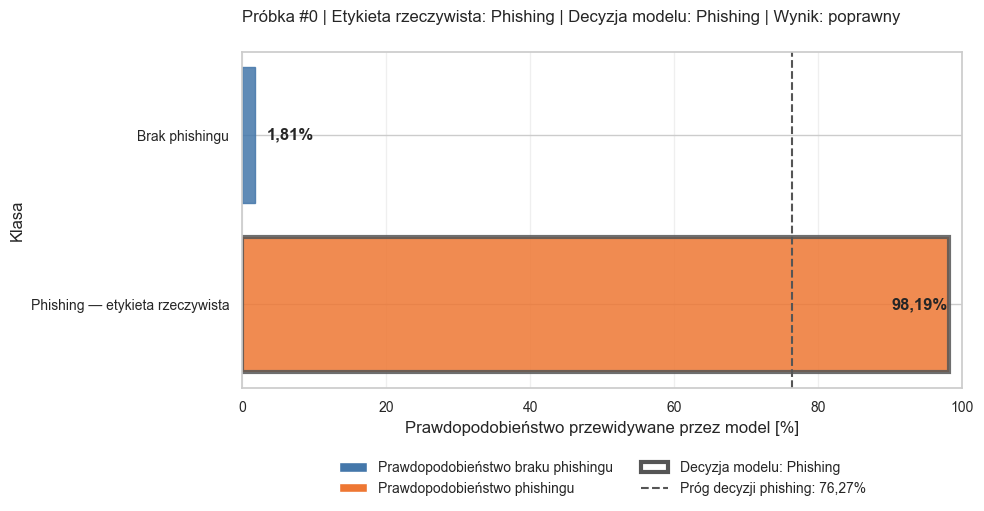

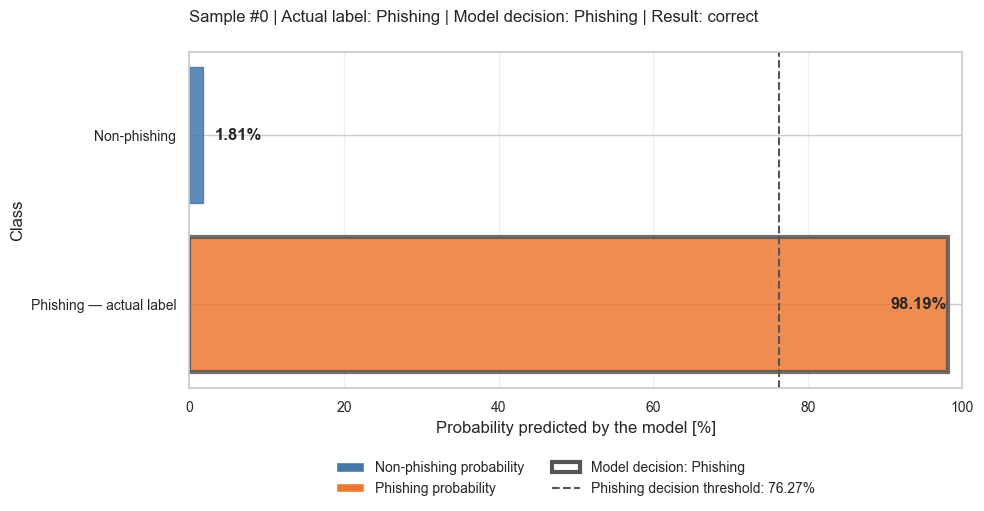

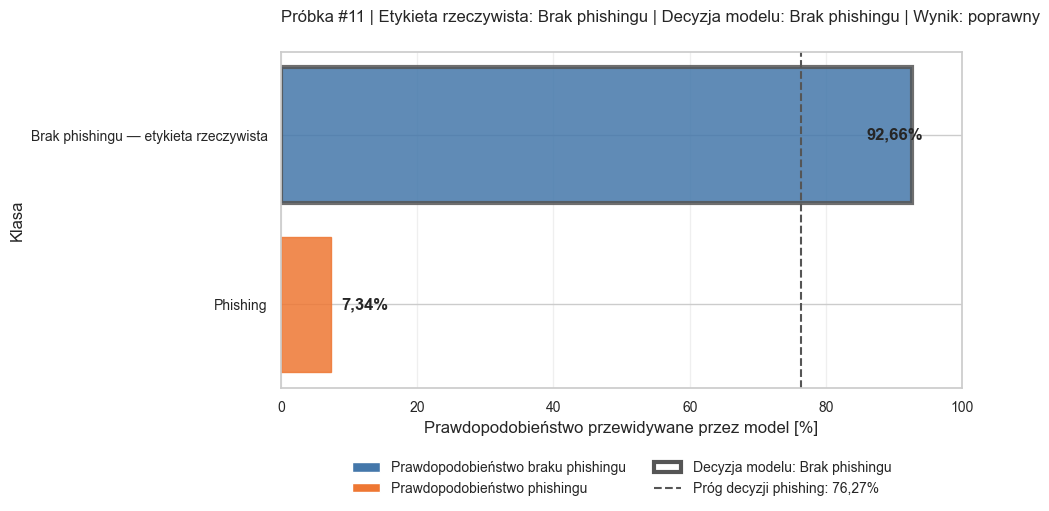

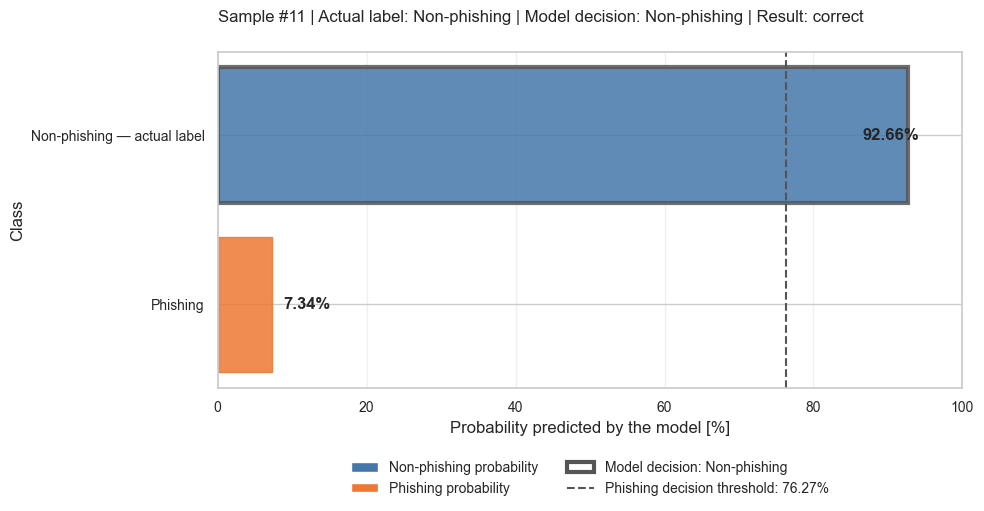

In [11]:
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    true_labels = train_test_data[dataset_name]['y_test']
    label_values = np.asarray(true_labels, dtype=int)
    probabilities = np.asarray(
        evaluation_results[dataset_name]['y_pred_proba'], dtype=float
    ).reshape(-1)
    threshold = evaluation_results[dataset_name].get('decision_threshold', 0.5)
    sample_positions = {
        'phishing': int(np.flatnonzero(label_values == 1)[0]),
        'bez_phishingu': int(np.flatnonzero(label_values == 0)[0]),
    }
    for sample_kind, position in sample_positions.items():
        sample_id = (
            true_labels.index[position]
            if hasattr(true_labels, 'index') else position
        )
        for language in ['pl', 'en']:
            language_folder = 'pl' if language == 'pl' else 'eng'
            figure, _ = plot_sample_probability_prediction(
                probabilities[position], label_values[position], sample_id,
                decision_threshold=threshold, language=language,
            )
            save_dataset_figure(
                figure, PLOTS_DIR, dataset_name,
                f'{language_folder}/logistic_regression_sample_prediction_{sample_kind}.png',
            )
            plt.show()
    for obsolete_name in [
        'logistic_regression_decision_example_phishing.png',
        'logistic_regression_decision_example_bez_phishingu.png',
        'logistic_regression_decision_examples.png',
        'logistic_regression_probability_distribution.png',
        'logistic_regression_sample_prediction_phishing.png',
        'logistic_regression_sample_prediction_bez_phishingu.png',
        'logistic_regression_sample_prediction_phishing_pl.png',
        'logistic_regression_sample_prediction_phishing_en.png',
        'logistic_regression_sample_prediction_bez_phishingu_pl.png',
        'logistic_regression_sample_prediction_bez_phishingu_en.png',
    ]:
        remove_dataset_figure(PLOTS_DIR, dataset_name, obsolete_name)


## 7.2. Krzywe uczenia w pięciokrotnej walidacji krzyżowej

Oś pozioma przedstawia dziesięć rosnących rozmiarów podzbioru uczącego: od
10% do 100% danych dostępnych do uczenia w danym podziale. Dla każdego rozmiaru
model jest dopasowywany w pięciu podziałach. Każdy punkt linii uczenia jest
średnią miary obliczonej na pięciu podzbiorach uczących, a każdy punkt linii
walidacji jest średnią miary obliczonej na pięciu odpowiadających im
podzbiorach walidacyjnych. Pasmo oznacza ± jedno odchylenie standardowe.
Oś pozioma nie przedstawia liczby próbek walidacyjnych ani testowych.

Walidacja służy do oceny uogólniania modelu podczas jego opracowywania.
Nie jest testem końcowym. Niezależny zbiór testowy nie uczestniczy w
wyznaczaniu tych krzywych; porównanie końcowych wyników uczenia i testowania
znajduje się w sekcji ewaluacji modelu.


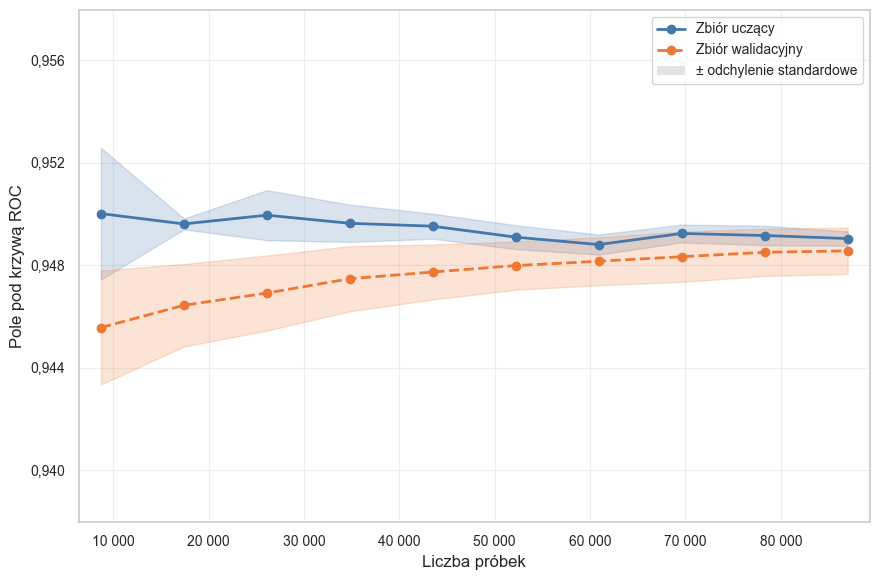

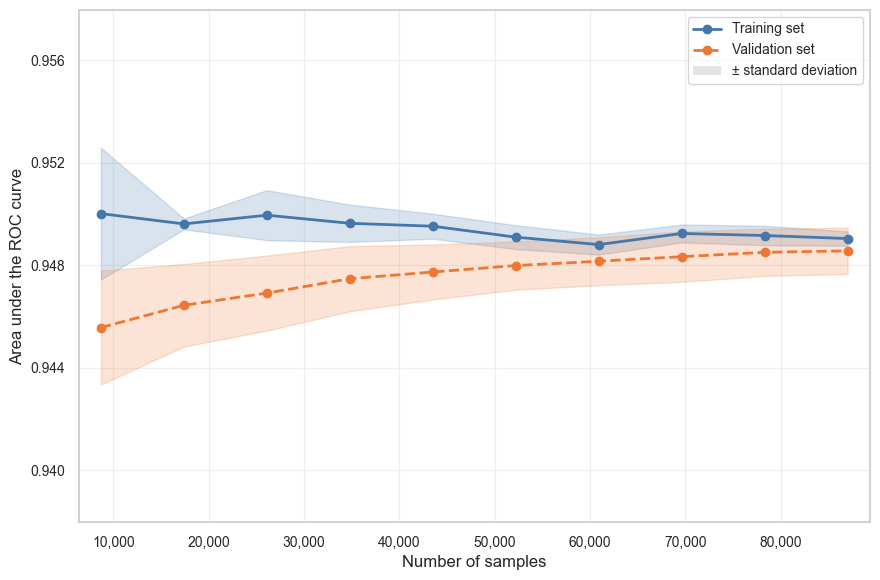

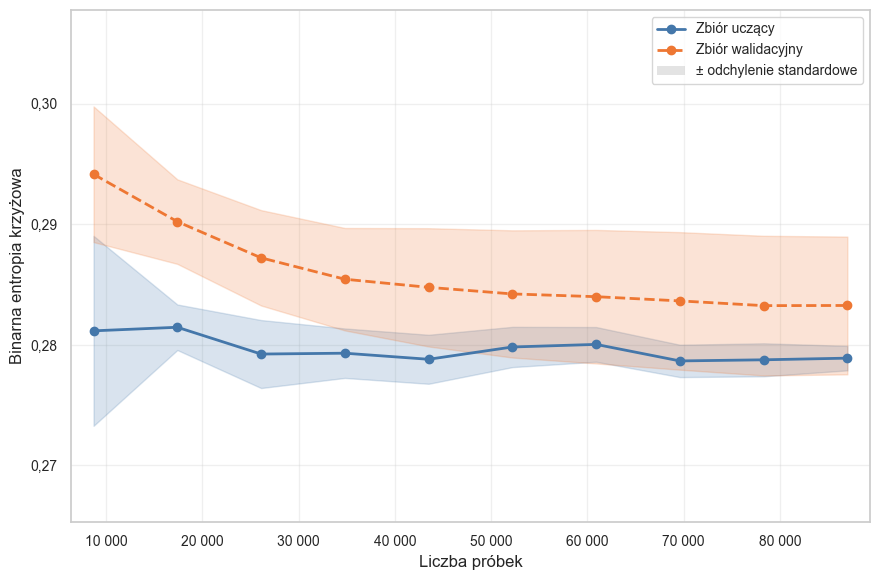

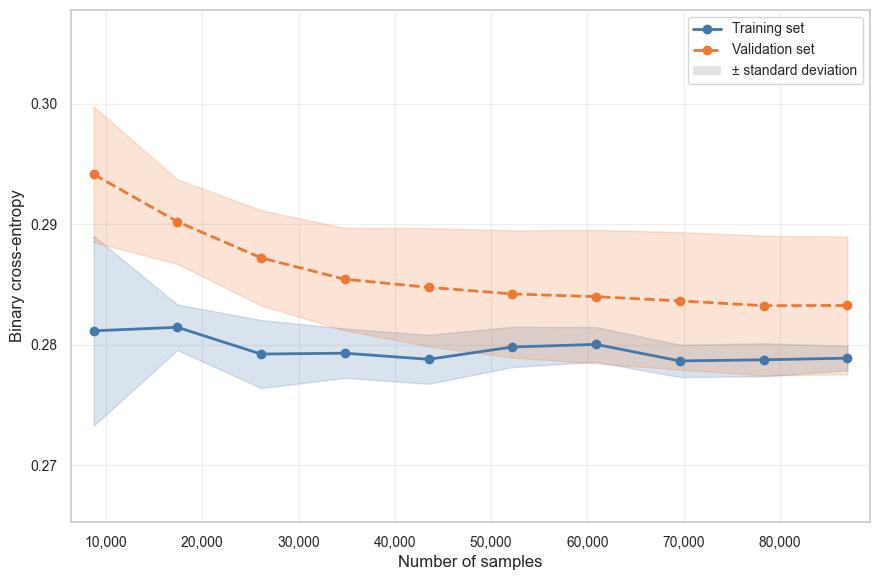

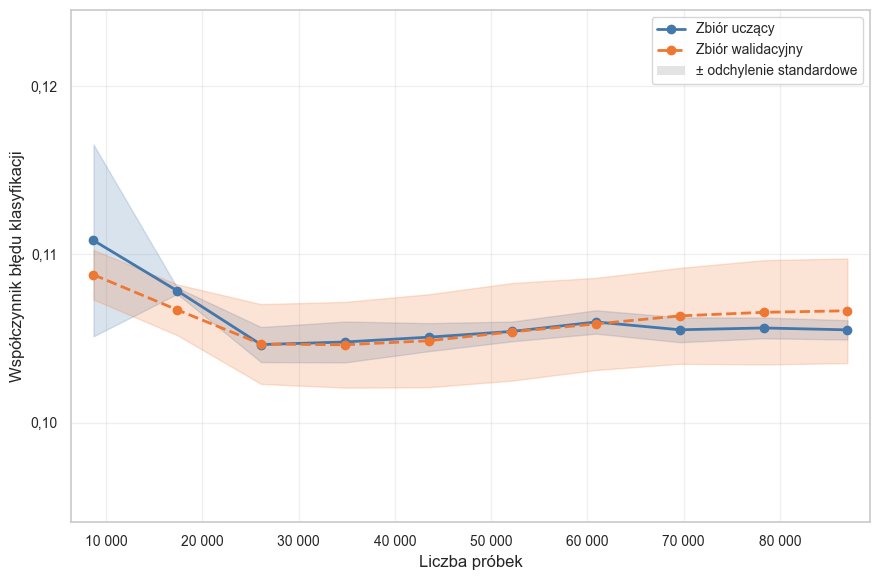

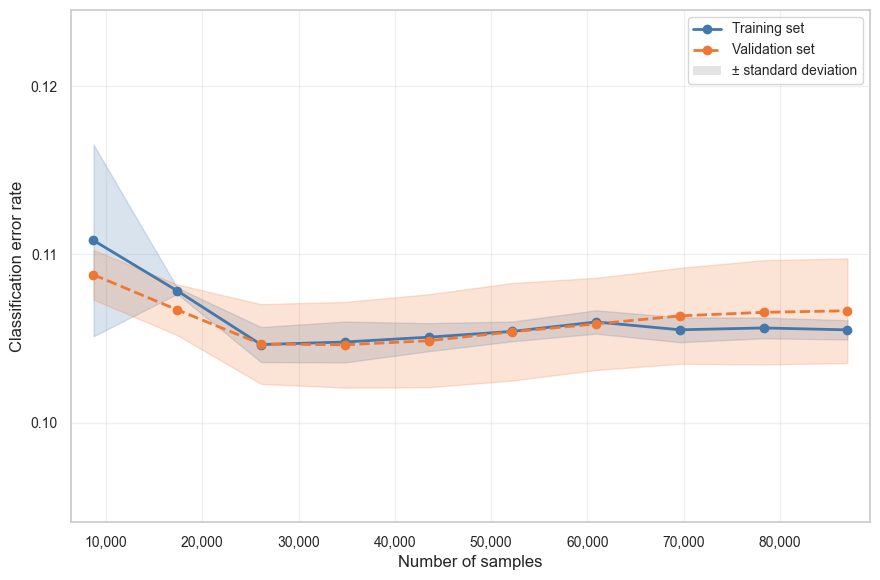

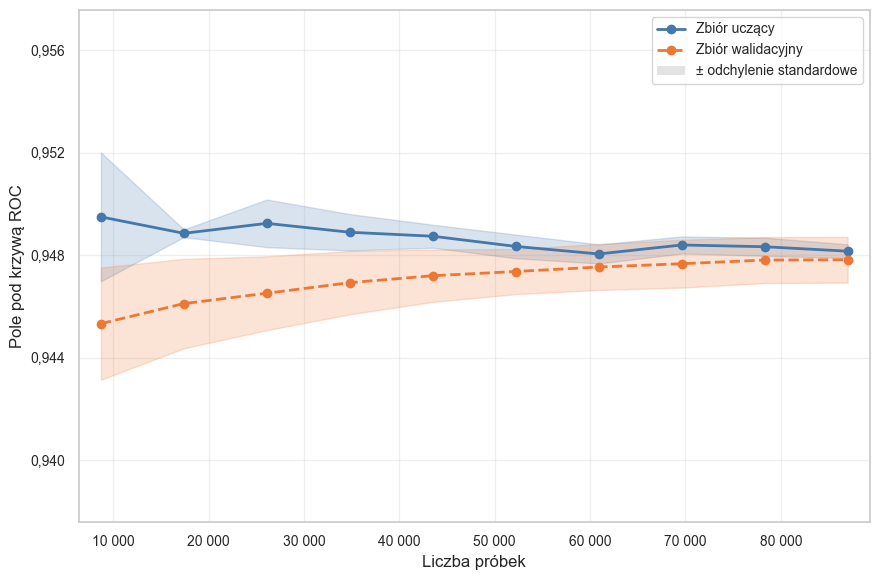

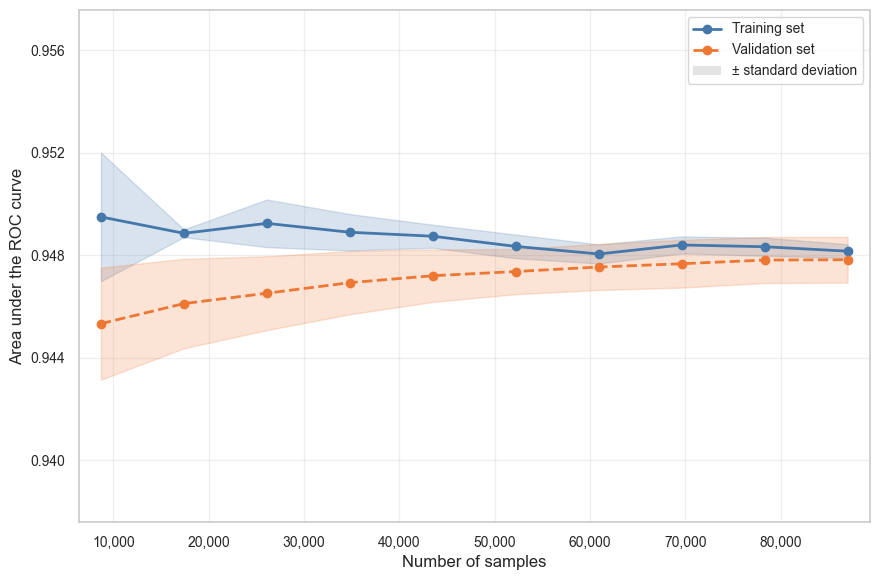

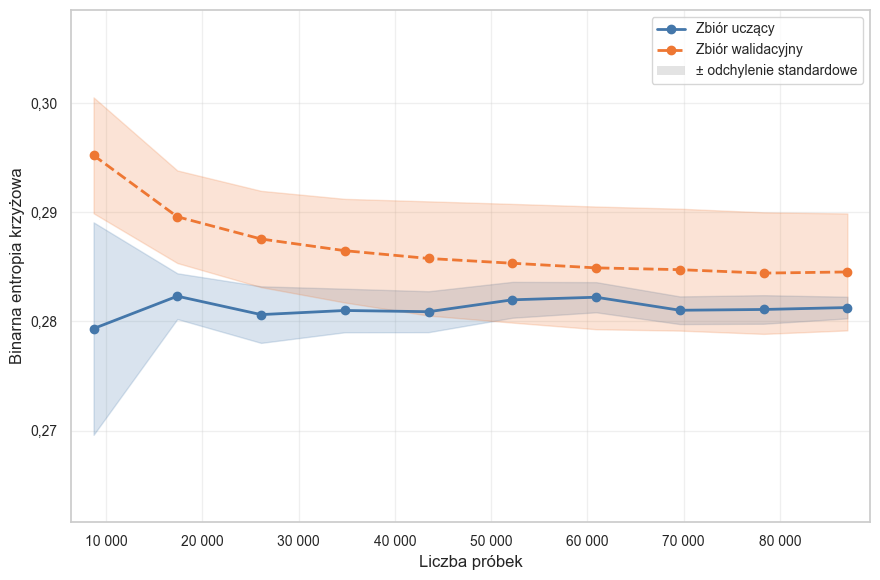

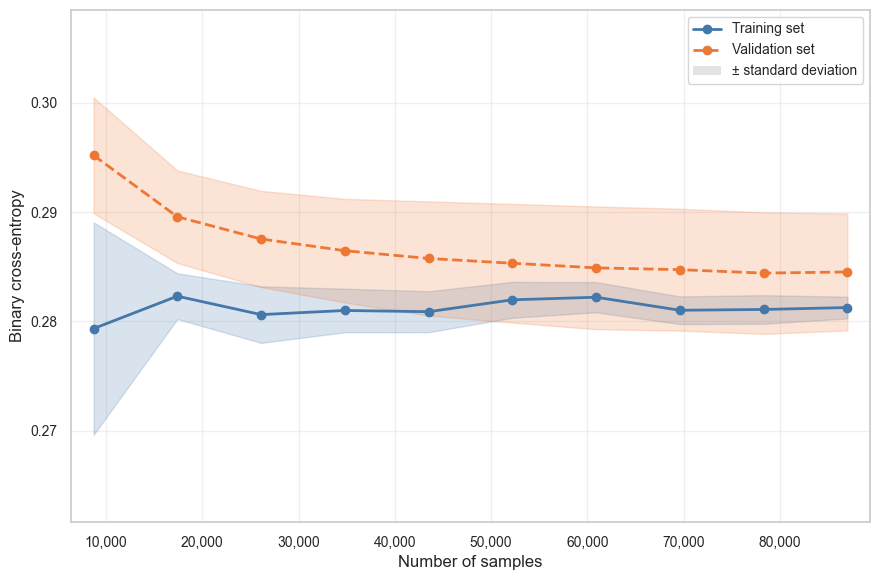

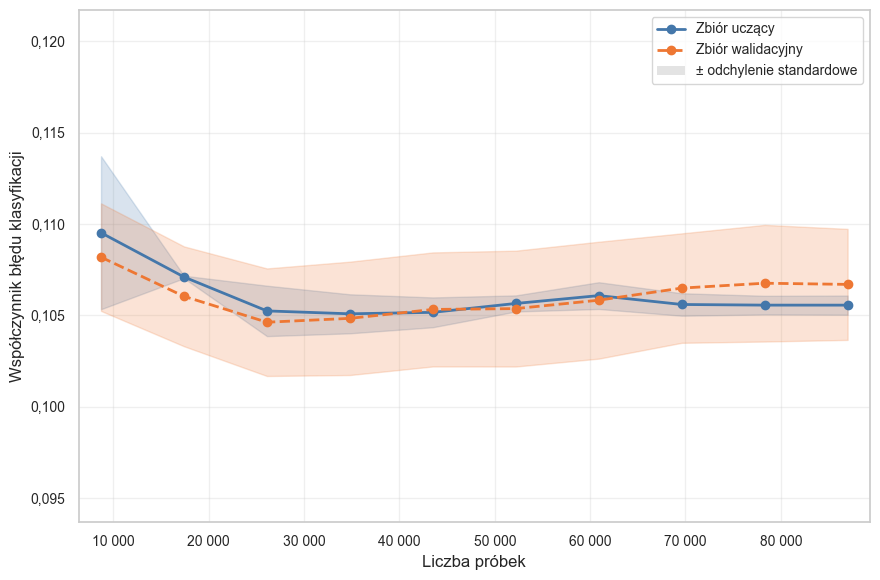

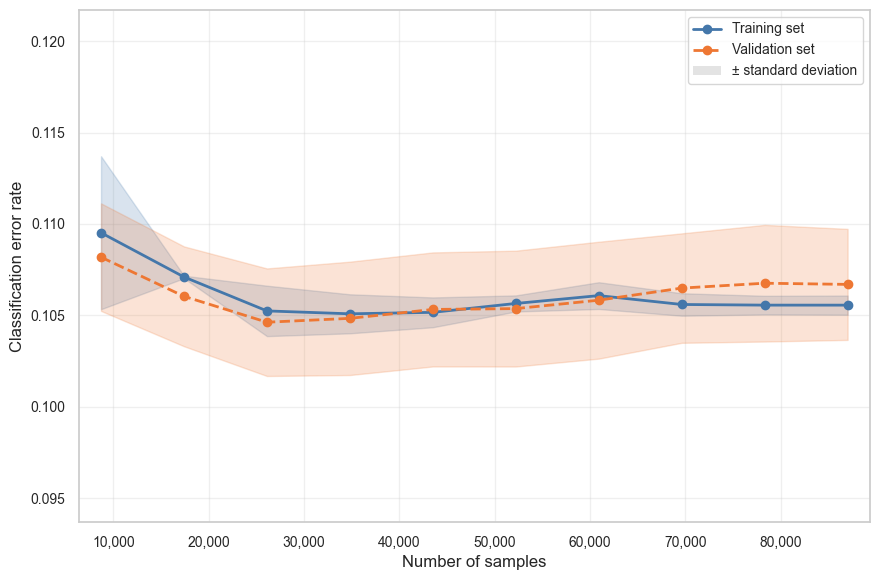

In [12]:
learning_results = {}
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    model = trained_models[dataset_name]['model']
    X_curve = train_test_data[dataset_name]['X_train_scaled']
    y_curve = train_test_data[dataset_name]['y_train']

    train_sizes, train_scores, validation_scores = learning_curve(
        model, train_test_data[dataset_name]['X_train_scaled'], train_test_data[dataset_name]['y_train'], cv=5, scoring='roc_auc', n_jobs=-1,
        train_sizes=np.linspace(0.1, 1.0, 10), random_state=42,
    )
    _, train_log_loss, validation_log_loss = learning_curve(
        model, X_curve, y_curve, cv=5, scoring='neg_log_loss', n_jobs=-1,
        train_sizes=np.linspace(0.1, 1.0, 10), random_state=42,
    )
    _, train_accuracy, validation_accuracy = learning_curve(
        model, X_curve, y_curve, cv=5, scoring='accuracy', n_jobs=-1,
        train_sizes=np.linspace(0.1, 1.0, 10), random_state=42,
    )
    learning_results[dataset_name] = {
        'x': train_sizes,
        'train_mean': train_scores.mean(axis=1),
        'train_std': train_scores.std(axis=1),
        'validation_mean': validation_scores.mean(axis=1),
        'validation_std': validation_scores.std(axis=1),
        'train_log_loss_mean': (-train_log_loss).mean(axis=1),
        'train_log_loss_std': (-train_log_loss).std(axis=1),
        'validation_log_loss_mean': (-validation_log_loss).mean(axis=1),
        'validation_log_loss_std': (-validation_log_loss).std(axis=1),
        'train_error_rate_mean': (1.0 - train_accuracy).mean(axis=1),
        'train_error_rate_std': train_accuracy.std(axis=1),
        'validation_error_rate_mean': (1.0 - validation_accuracy).mean(axis=1),
        'validation_error_rate_std': validation_accuracy.std(axis=1),
    }

for dataset_name, values in learning_results.items():
    figure, _ = plot_score_curve(
        values['x'], values['train_mean'], values['train_std'],
        values['validation_mean'], values['validation_std'],
        x_label='Liczba próbek',
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'logistic_regression_learning_curves.png')
    plt.show()

    figure, _ = plot_score_curve(
        values['x'], values['train_log_loss_mean'], values['train_log_loss_std'],
        values['validation_log_loss_mean'], values['validation_log_loss_std'],
        x_label='Liczba próbek',
        y_label='Binarna entropia krzyżowa',
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'logistic_regression_bce_learning_curves.png')
    plt.show()

    figure, _ = plot_score_curve(
        values['x'], values['train_error_rate_mean'], values['train_error_rate_std'],
        values['validation_error_rate_mean'], values['validation_error_rate_std'],
        x_label='Liczba próbek',
        y_label='Współczynnik błędu klasyfikacji',
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'logistic_regression_error_rate_learning_curves.png')
    plt.show()


## 7.3. Wpływ regularyzacji (parametr C) na skuteczność modelu


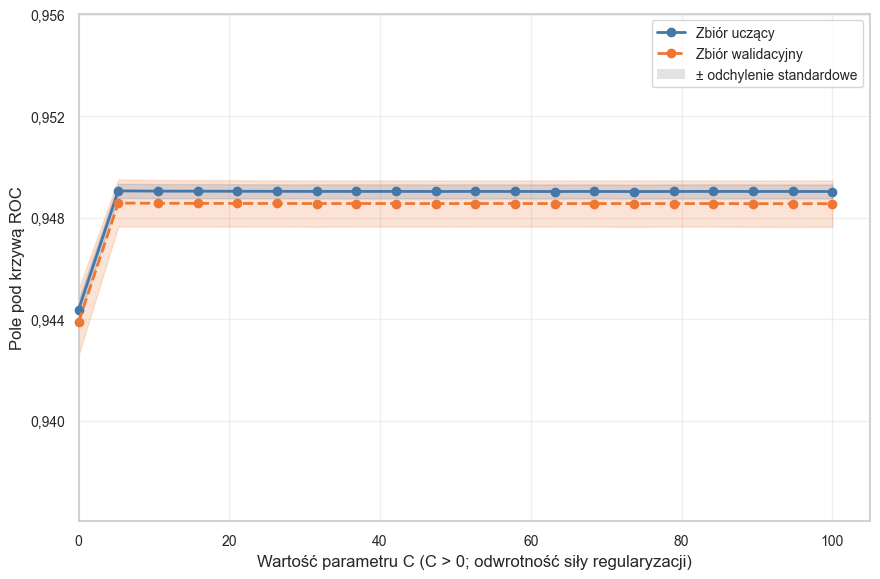

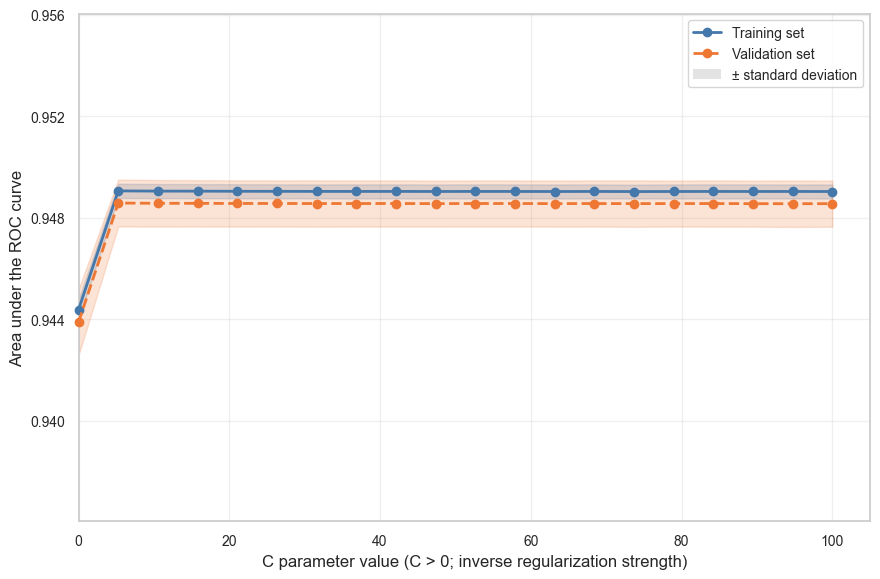

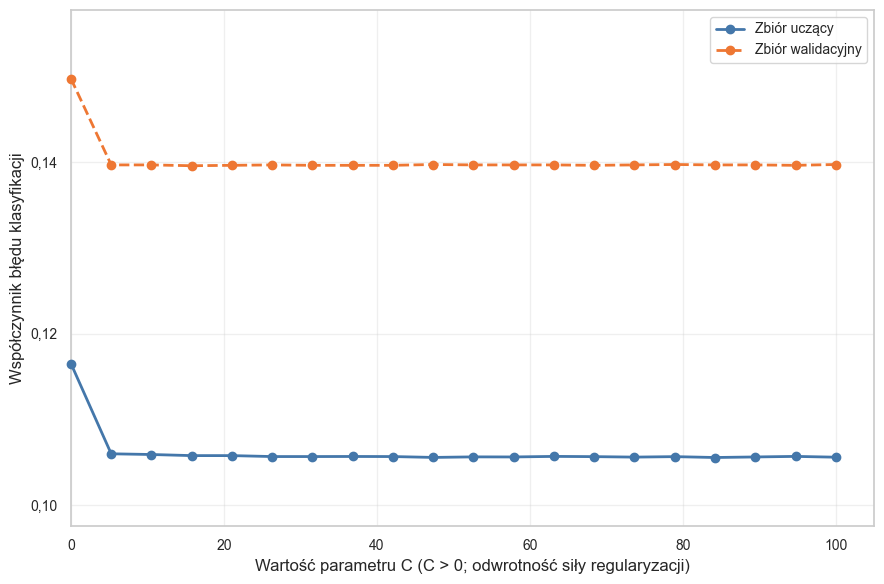

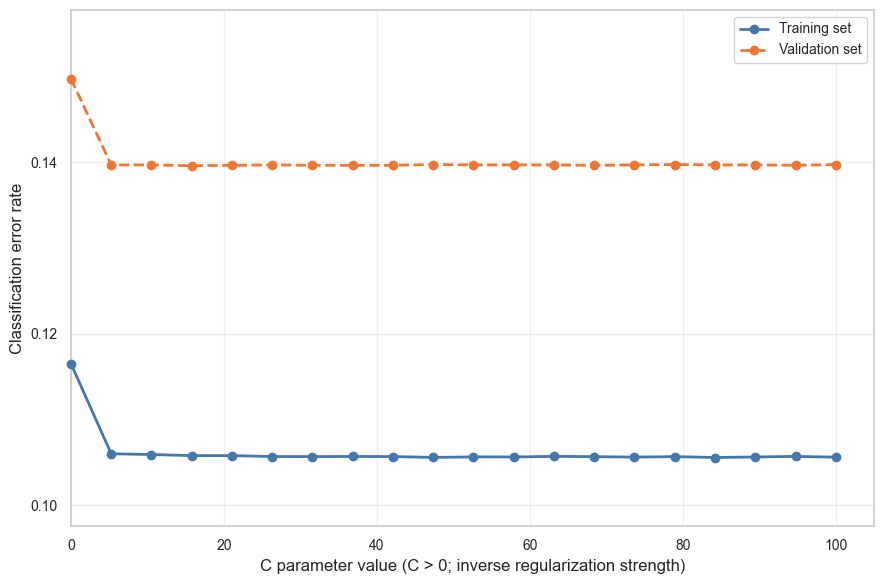

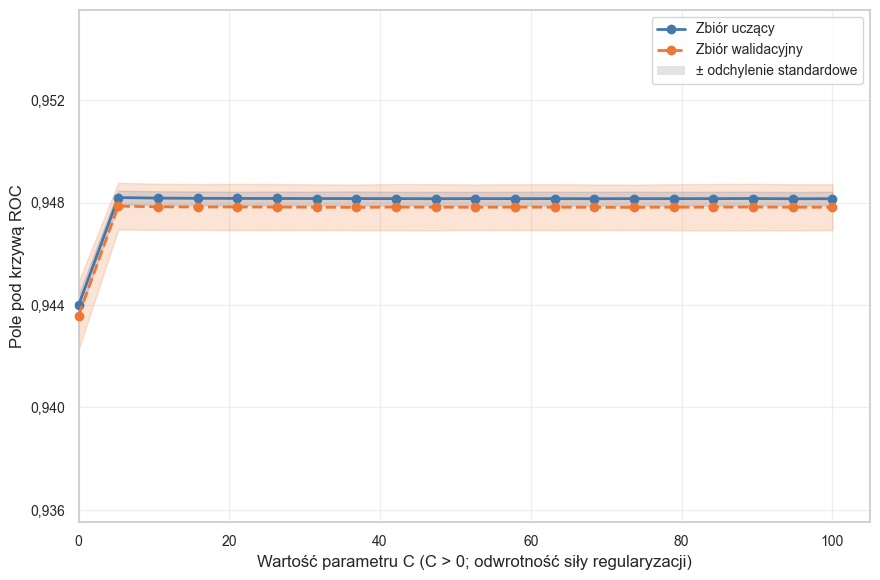

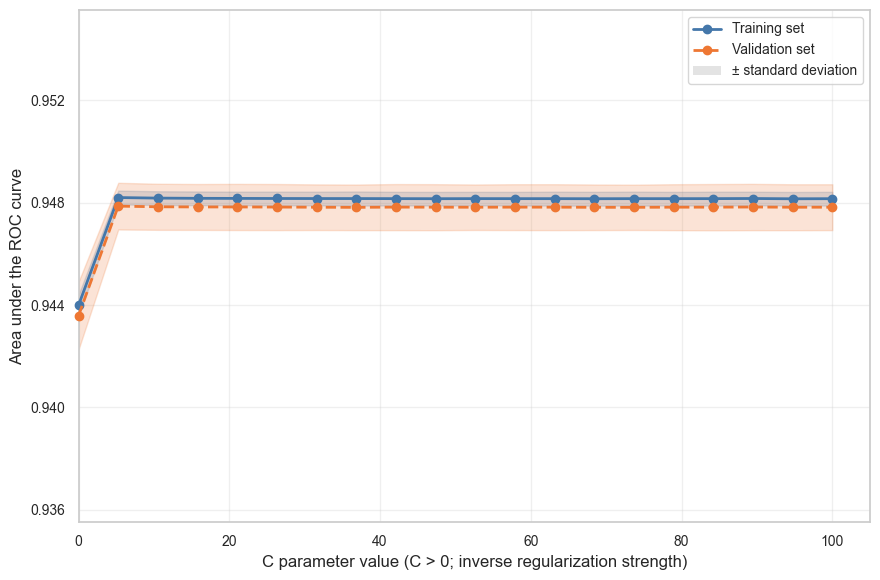

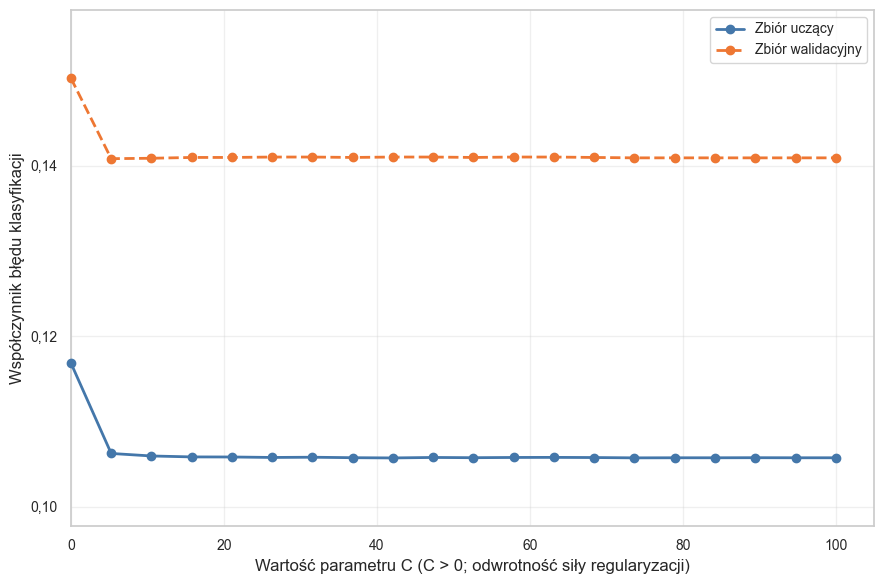

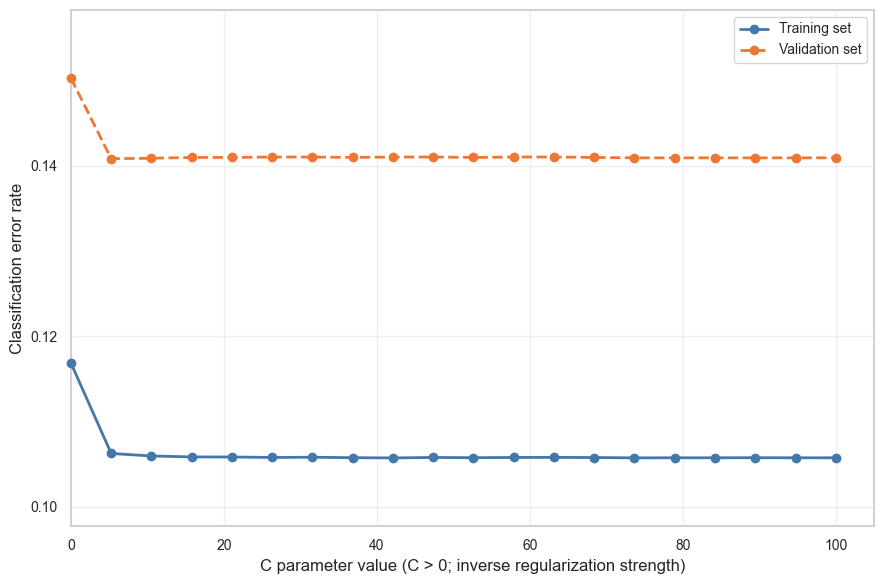

In [13]:
validation_results = {}
param_range = np.linspace(0.01, 100.0, 20)
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    X_curve = train_test_data[dataset_name]['X_train_scaled']
    y_curve = train_test_data[dataset_name]['y_train']
    X_val_curve = train_test_data[dataset_name]['X_test_scaled']
    y_val_curve = train_test_data[dataset_name]['y_test']

    model_base = LogisticRegression(solver='liblinear', max_iter=1000, random_state=42)
    train_scores, validation_scores = validation_curve(
        model_base, X_curve, y_curve, param_name='C', param_range=param_range,
        cv=5, scoring='roc_auc', n_jobs=-1,
    )
    validation_results[dataset_name] = {
        'train_mean': train_scores.mean(axis=1),
        'train_std': train_scores.std(axis=1),
        'validation_mean': validation_scores.mean(axis=1),
        'validation_std': validation_scores.std(axis=1),
        'train_errors': [],
        'validation_errors': [],
    }
    for parameter_value in param_range:
        parameter_model = LogisticRegression(
            C=parameter_value, solver='liblinear', max_iter=1000,
            random_state=42,
        )
        parameter_model.fit(X_curve, y_curve)
        validation_results[dataset_name]['train_errors'].append(
            1.0 - accuracy_score(y_curve, parameter_model.predict(X_curve))
        )
        validation_results[dataset_name]['validation_errors'].append(
            1.0 - accuracy_score(y_val_curve, parameter_model.predict(X_val_curve))
        )

for dataset_name, values in validation_results.items():
    figure, _ = plot_score_curve(
        param_range, values['train_mean'], values['train_std'],
        values['validation_mean'], values['validation_std'],
        x_label='Wartość parametru C (C > 0; odwrotność siły regularyzacji)', logarithmic_x=False,
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'logistic_regression_validation_curves.png')
    plt.show()
    figure, _ = plot_parameter_train_validation_error(
        param_range, values['train_errors'], values['validation_errors'],
        x_label='Wartość parametru C (C > 0; odwrotność siły regularyzacji)', logarithmic_x=False,
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'logistic_regression_parameter_train_validation_error.png')
    plt.show()


## 7.4. Tabela porównawcza wyników


In [14]:
comparison_df = pd.DataFrame({
    'Zbiór danych': ['Pełny zbiór', 'Zoptymalizowany zbiór'],
    'Dokładność': [evaluation_results['Pełny zbiór']['accuracy'], evaluation_results['Zoptymalizowany zbiór']['accuracy']],
    'Precyzja': [evaluation_results['Pełny zbiór']['precision'], evaluation_results['Zoptymalizowany zbiór']['precision']],
    'Czułość': [evaluation_results['Pełny zbiór']['recall'], evaluation_results['Zoptymalizowany zbiór']['recall']],
    'FPR (odsetek fałszywie dodatnich)': [evaluation_results['Pełny zbiór']['false_positive_rate'], evaluation_results['Zoptymalizowany zbiór']['false_positive_rate']],
    'Próg decyzyjny': [evaluation_results['Pełny zbiór']['decision_threshold'], evaluation_results['Zoptymalizowany zbiór']['decision_threshold']],
    'Miara F1': [evaluation_results['Pełny zbiór']['f1'], evaluation_results['Zoptymalizowany zbiór']['f1']],
    'AUC-ROC': [evaluation_results['Pełny zbiór']['auc_roc'], evaluation_results['Zoptymalizowany zbiór']['auc_roc']],
    'Średnia CV AUC': [evaluation_results['Pełny zbiór']['cv_mean'], evaluation_results['Zoptymalizowany zbiór']['cv_mean']],
    'Odchylenie CV AUC': [evaluation_results['Pełny zbiór']['cv_std'], evaluation_results['Zoptymalizowany zbiór']['cv_std']],
    'Czas uczenia (s)': [trained_models['Pełny zbiór']['training_time'], trained_models['Zoptymalizowany zbiór']['training_time']],
    'Liczba cech': [data_splits['Pełny zbiór']['feature_count'], data_splits['Zoptymalizowany zbiór']['feature_count']],
    'Średnie CPU [%]': [resource_stats[name]['stats']['cpu']['mean'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Maksymalne CPU [%]': [resource_stats[name]['stats']['cpu']['max'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Średni RAM [GB]': [resource_stats[name]['stats']['ram']['mean'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Maksymalny RAM [GB]': [resource_stats[name]['stats']['ram']['max'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Próbki pomiarowe': [resource_stats[name]['stats']['samples'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']]
})

comparison_path = backend_root.parent / 'results' / 'url_corpus' / 'model_comparisons' / 'logistic_regression_comparison.csv'
comparison_path.parent.mkdir(parents=True, exist_ok=True)
comparison_df.to_csv(comparison_path, index=False)
print(f"✓ Porównanie zapisane: {comparison_path}")
print("\nTabela porównawcza:")
print(comparison_df.to_string(index=False))

✓ Porównanie zapisane: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/url_corpus/model_comparisons/logistic_regression_comparison.csv

Tabela porównawcza:
         Zbiór danych  Dokładność  Precyzja  Czułość  FPR (odsetek fałszywie dodatnich)  Próg decyzyjny  Miara F1  AUC-ROC  Średnia CV AUC  Odchylenie CV AUC  Czas uczenia (s)  Liczba cech  Średnie CPU [%]  Maksymalne CPU [%]  Średni RAM [GB]  Maksymalny RAM [GB]  Próbki pomiarowe
          Pełny zbiór    0.850667  0.935225 0.753524                           0.052190        0.764848  0.834599 0.903600        0.948553           0.000909         24.042590          110         9.089268           10.739531         0.495351             0.495834               396
Zoptymalizowany zbiór    0.849857  0.933758 0.753143                           0.053429        0.762676  0.833781 0.898644        0.947822           0.000896          2.981744           47         9.038966           10.049308         0.330386         

## 7.5. Ważność cech w obu modelach


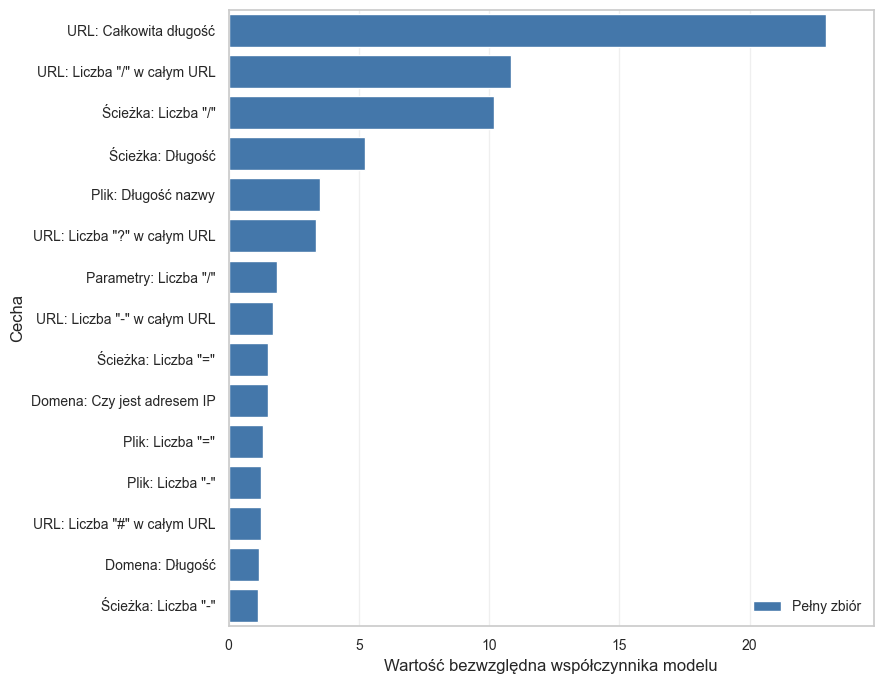

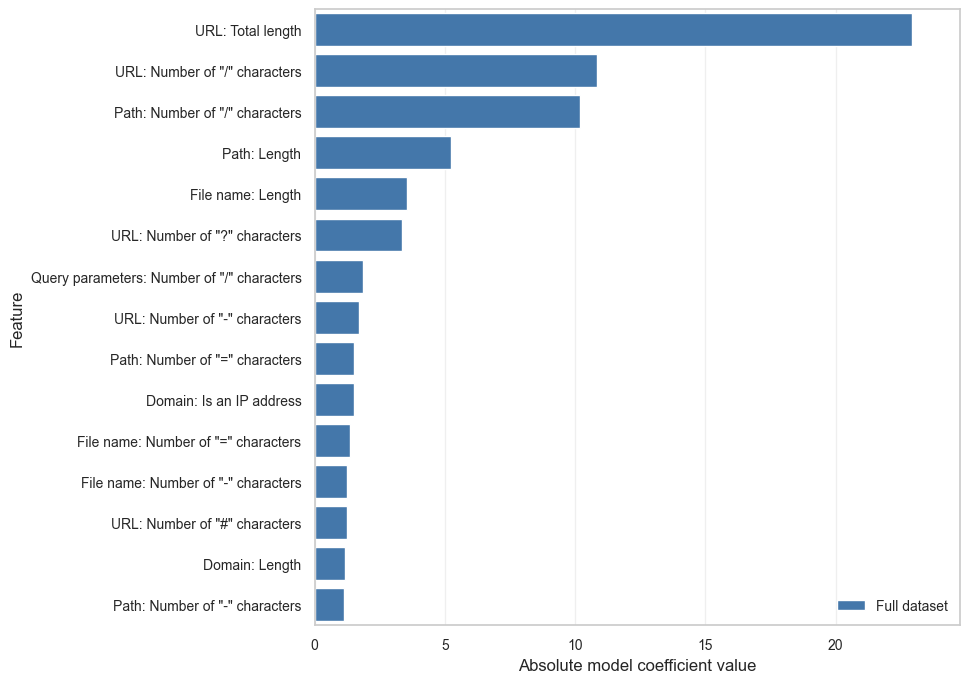

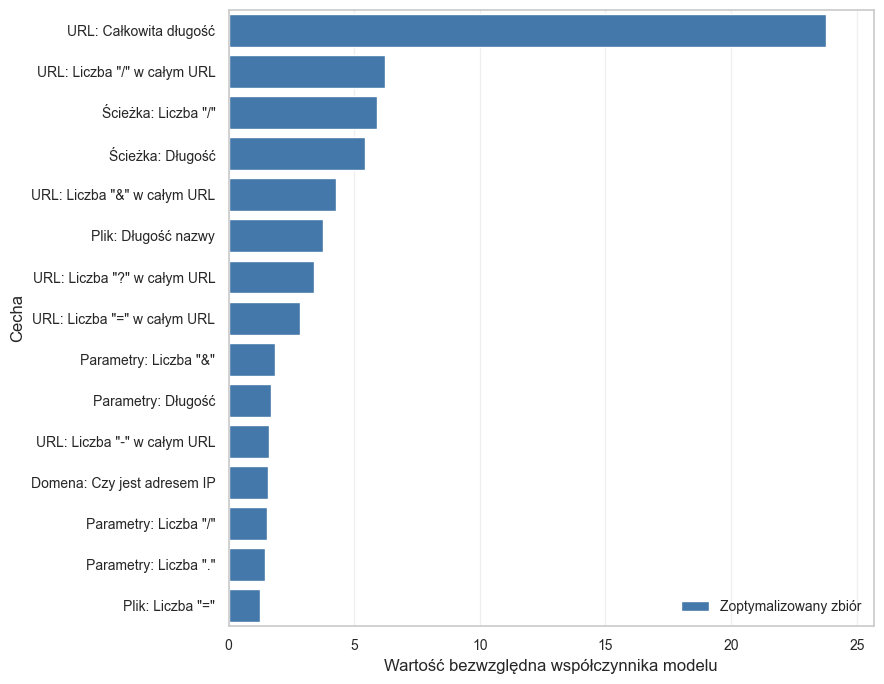

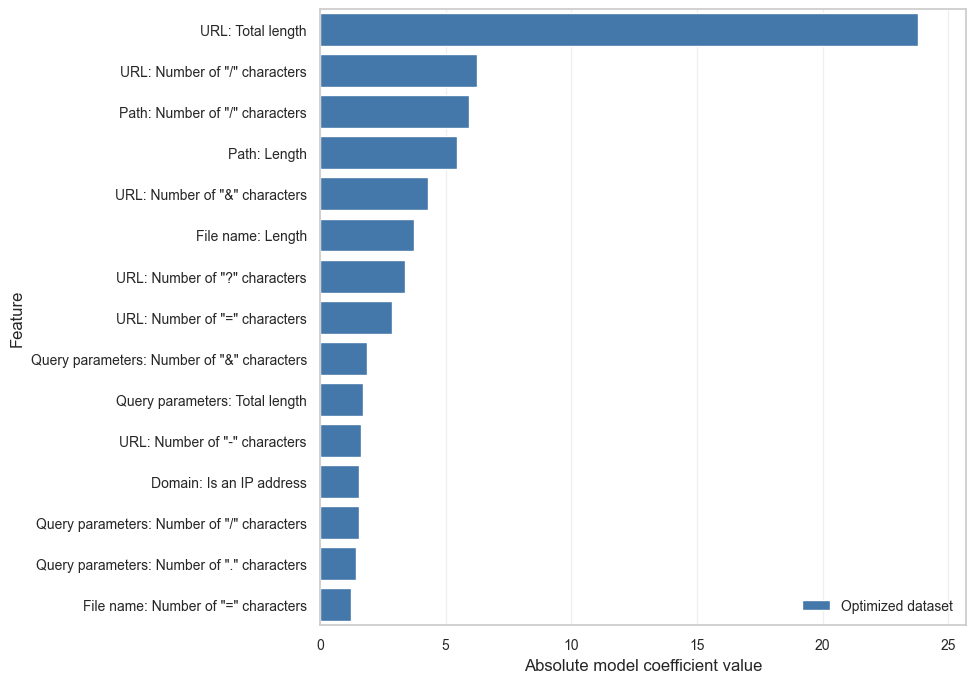

In [15]:
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    model = trained_models[dataset_name]['model']
    X_features = train_test_data[dataset_name]['X_train']
    feature_importance = pd.DataFrame({
        'Cecha': [get_readable_name(column) for column in X_features.columns],
        'Ważność': np.abs(model.coef_[0]),
    }).sort_values('Ważność', ascending=False).head(15)
    figure, _ = plot_feature_ranking(
        feature_importance, dataset_name, x_column='Ważność', x_label='Wartość bezwzględna współczynnika modelu'
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'logistic_regression_feature_importance.png')
    plt.show()


## 7.6. Wizualizacja architektury regresji logistycznej



PEŁNY ZBIÓR


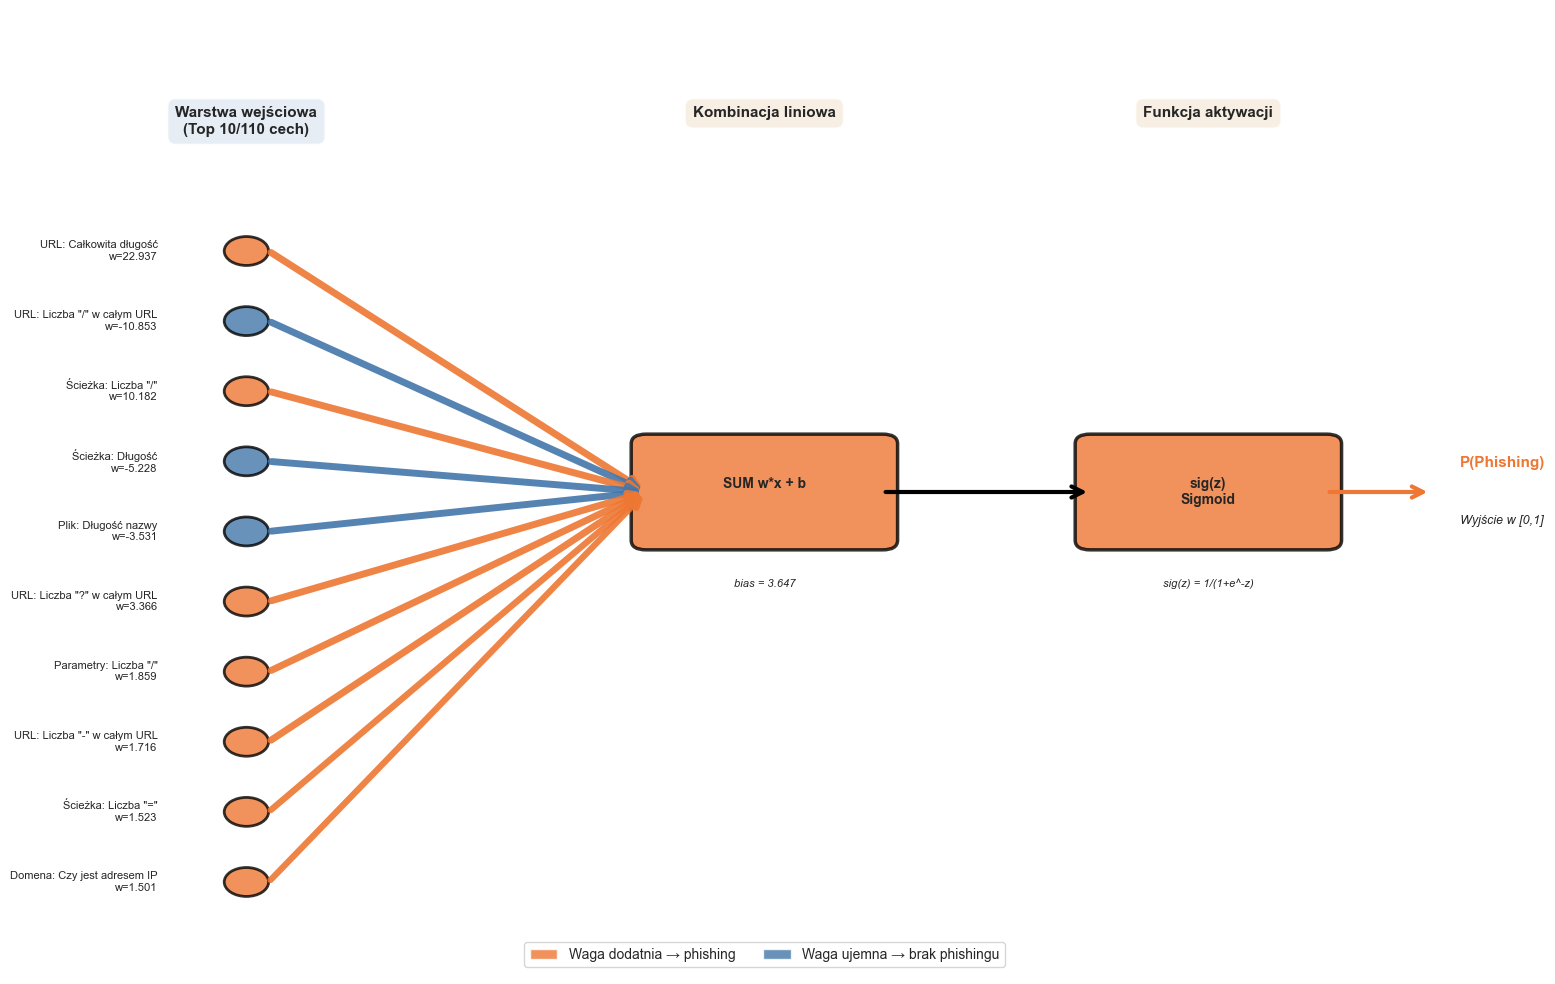

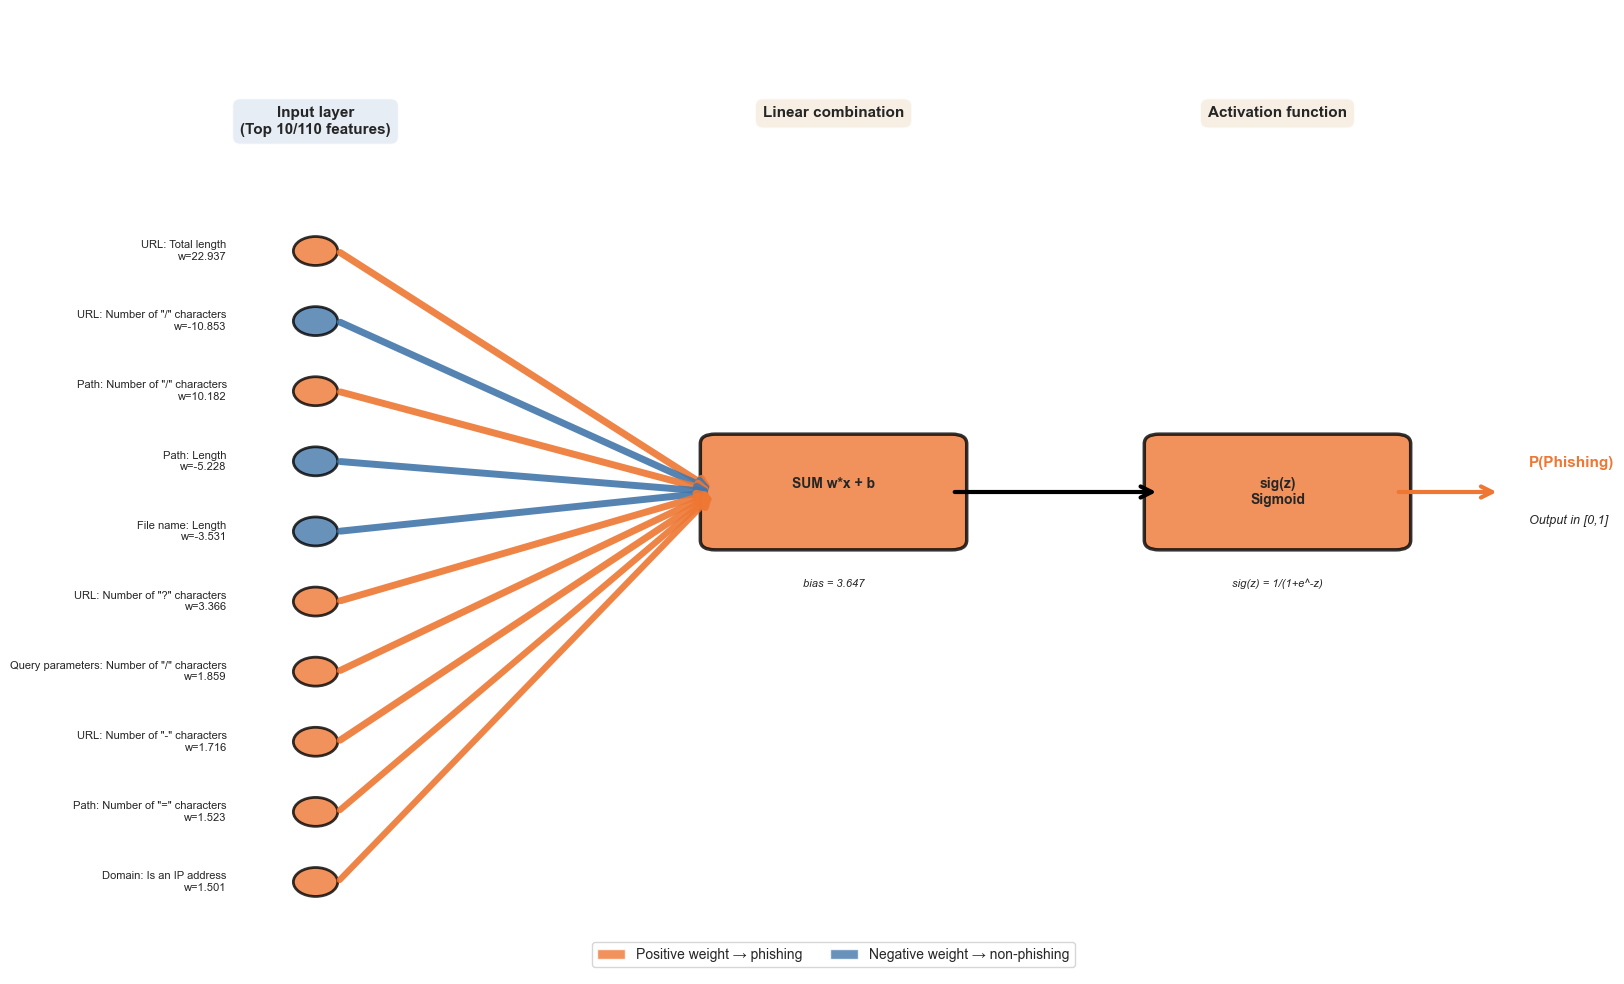


ZOPTYMALIZOWANY ZBIÓR


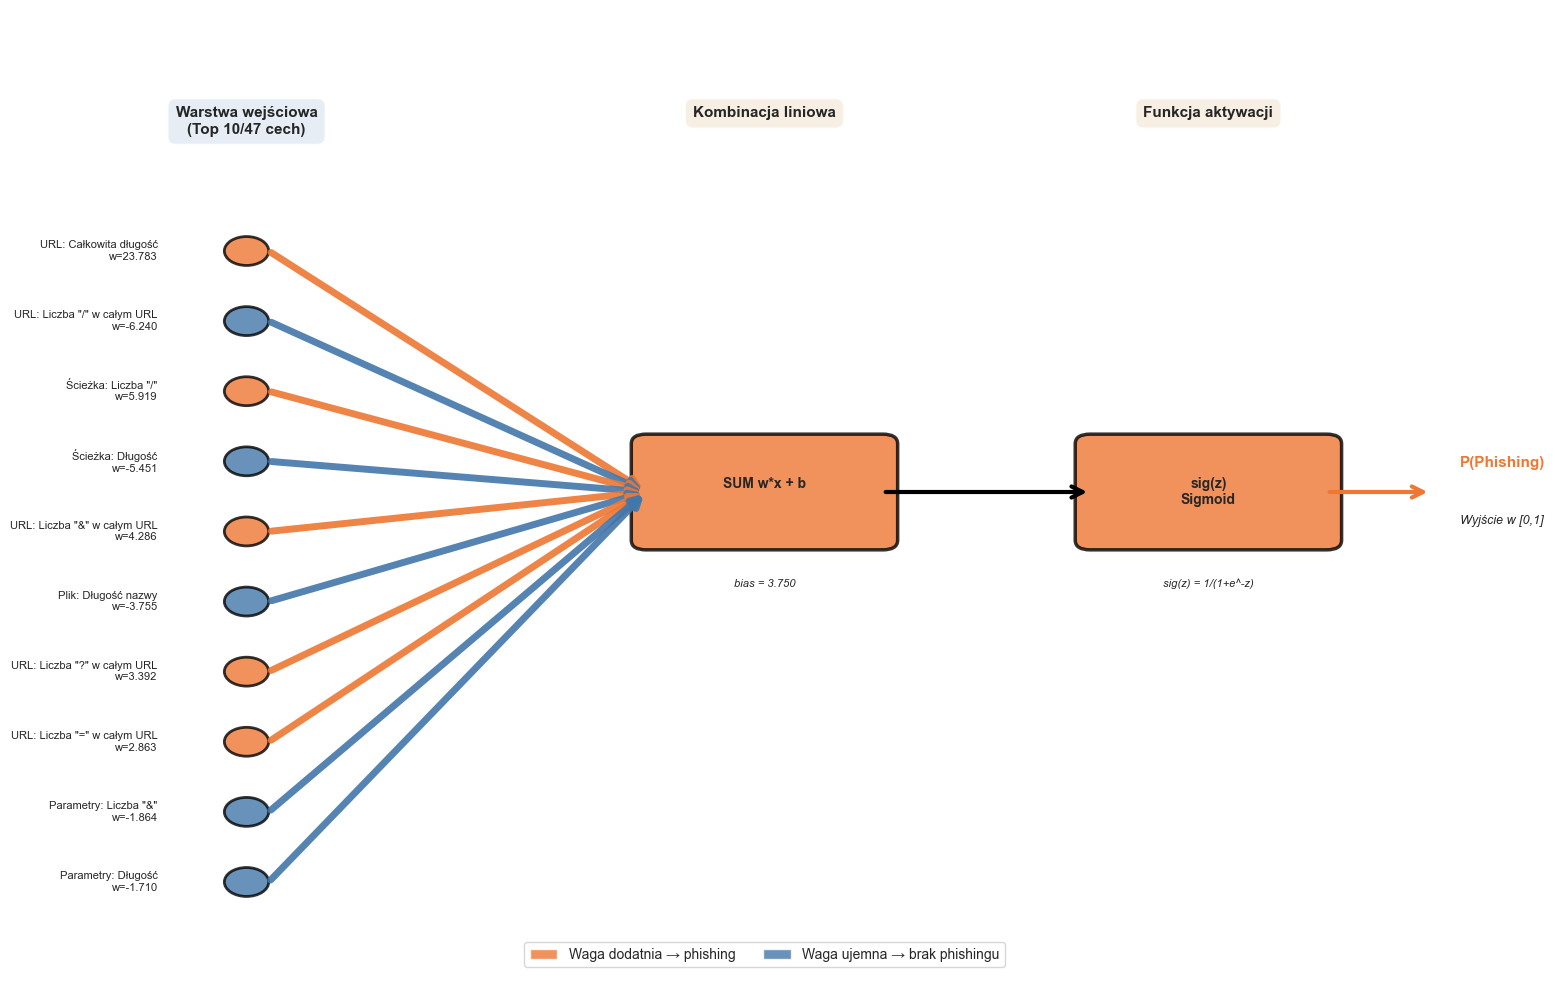

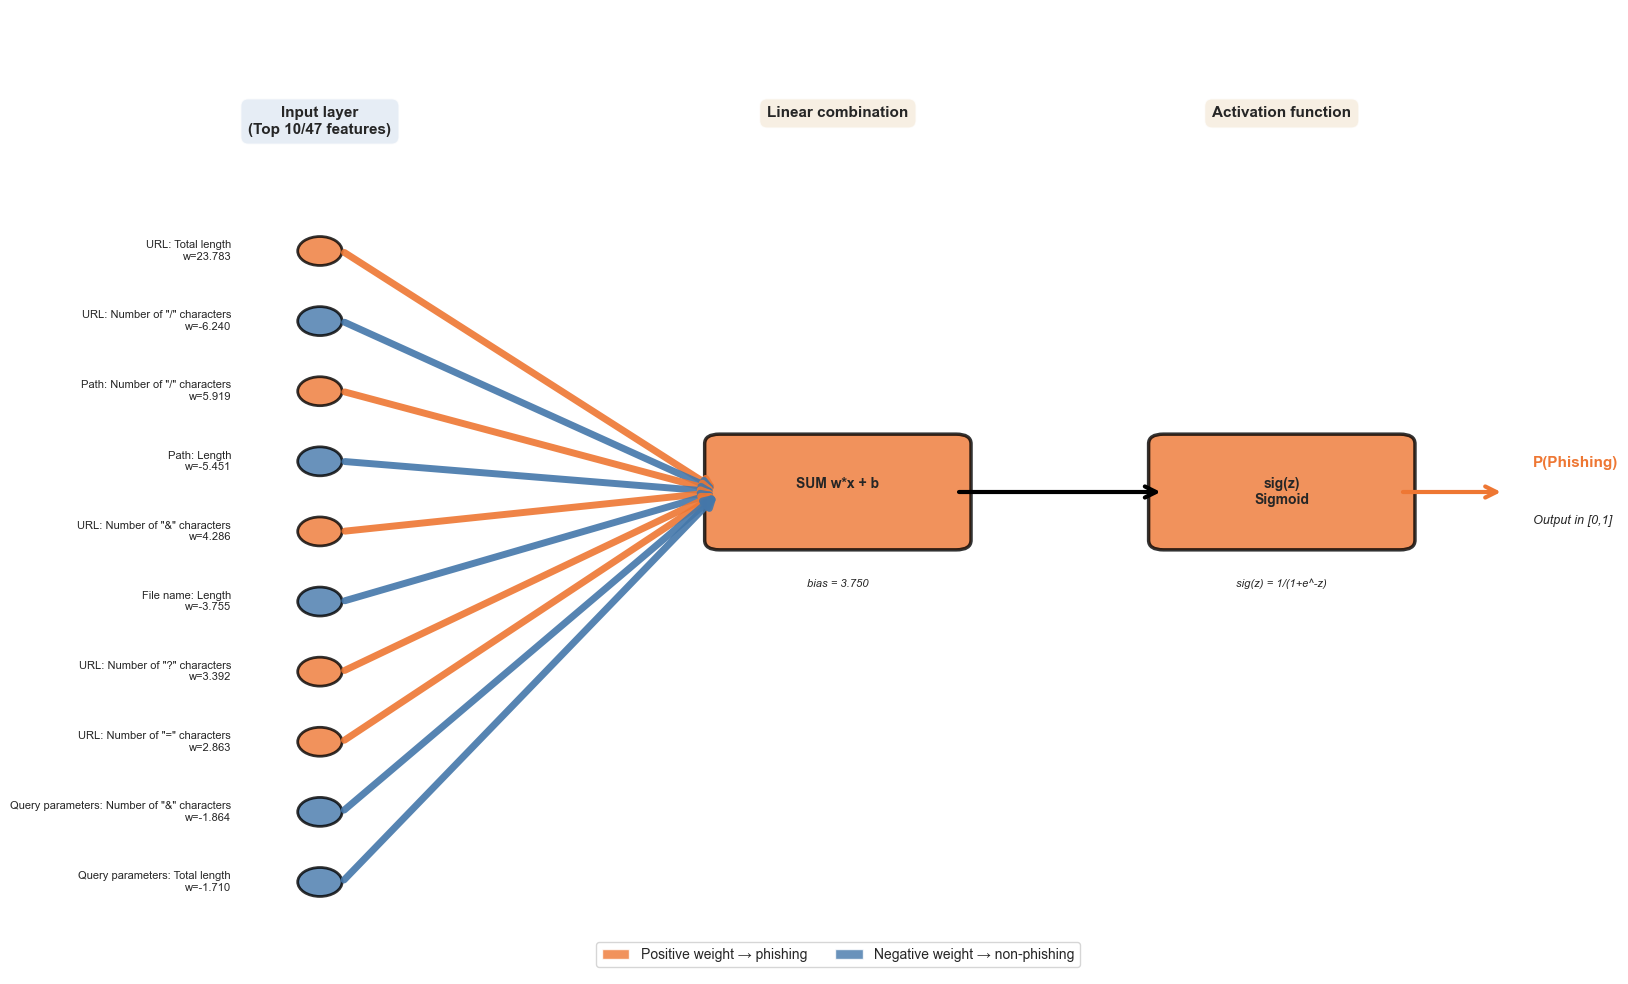

✅ Wizualizacja architektury modelu zapisana


In [16]:
dataset_names = list(trained_models.keys())
dataset_display = [dataset_display_name(name, data_splits[name]['feature_count']) for name in data_splits]

for idx, dataset_name in enumerate(dataset_names):
    print(f"\n{'='*80}")
    print(f"{dataset_name.upper()}")
    print(f"{'='*80}")

    subdir = DATASET_SUBDIR[dataset_name]
    model = trained_models[dataset_name]['model']
    data = train_test_data[dataset_name]
    total_features = len(data['X_train'].columns)

    fig, ax = plt.subplots(figsize=(16, 10))
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 10)
    ax.axis('off')

    feature_weights = pd.DataFrame({
        'Cecha': [get_readable_name(col) for col in data['X_train'].columns],
        'Waga': model.coef_[0]
    }).sort_values('Waga', key=abs, ascending=False)

    top_n = 10
    top_features = feature_weights.head(top_n)

    input_layer_x = 1.5
    input_spacing = 8 / (top_n + 1)


    ax.text(input_layer_x, 9, f'Warstwa wejściowa\n(Top {top_n}/{total_features} cech)',
            ha='center', va='top', fontsize=11, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='#DCE6F2', alpha=0.7))

    input_nodes = []
    for i, (_, row) in enumerate(top_features.iterrows()):
        y_pos = 7.5 - i * input_spacing
        weight = row['Waga']
        color = CLASS_COLORS['phishing'] if weight > 0 else CLASS_COLORS['safe']

        circle = Circle((input_layer_x, y_pos), 0.15,
                       facecolor=color, edgecolor='black', linewidth=2, alpha=0.8)
        ax.add_patch(circle)
        input_nodes.append((input_layer_x, y_pos, weight))

        feature_text = f"{row['Cecha']}\nw={weight:.3f}"
        ax.text(input_layer_x - 0.6, y_pos, feature_text,
               ha='right', va='center', fontsize=8)

    linear_x = 5
    linear_y = 5

    ax.text(linear_x, 9, 'Kombinacja liniowa', ha='center', va='top',
           fontsize=11, fontweight='bold', bbox=dict(boxstyle='round,pad=0.5',
           facecolor='#F5E9D8', alpha=0.7))

    sum_box = FancyBboxPatch((linear_x - 0.8, linear_y - 0.5), 1.6, 1,
                            boxstyle="round,pad=0.1",
                            facecolor='#EE7733', edgecolor='black', linewidth=2.5, alpha=0.8)
    ax.add_patch(sum_box)

    ax.text(linear_x, linear_y, 'SUM w*x + b\n', ha='center', va='center',
           fontsize=10, fontweight='bold')
    ax.text(linear_x, linear_y - 0.9, f'bias = {model.intercept_[0]:.3f}',
           ha='center', va='top', fontsize=8, style='italic')

    for inp_x, inp_y, weight in input_nodes:
        linewidth = min(abs(weight) * 3, 5)
        color = CLASS_COLORS['phishing'] if weight > 0 else CLASS_COLORS['safe']
        alpha = min(abs(weight) * 0.5 + 0.3, 0.9)

        arrow = FancyArrowPatch((inp_x + 0.15, inp_y), (linear_x - 0.8, linear_y),
                               arrowstyle='->', mutation_scale=15,
                               color=color, linewidth=linewidth, alpha=alpha)
        ax.add_patch(arrow)

    sigmoid_x = 8
    sigmoid_y = 5

    ax.text(sigmoid_x, 9, 'Funkcja aktywacji', ha='center', va='top',
           fontsize=11, fontweight='bold', bbox=dict(boxstyle='round,pad=0.5',
           facecolor='#F5E9D8', alpha=0.7))

    sigmoid_box = FancyBboxPatch((sigmoid_x - 0.8, sigmoid_y - 0.5), 1.6, 1,
                                boxstyle="round,pad=0.1",
                                facecolor='#EE7733', edgecolor='black', linewidth=2.5, alpha=0.8)
    ax.add_patch(sigmoid_box)

    ax.text(sigmoid_x, sigmoid_y, 'sig(z)\nSigmoid', ha='center', va='center',
           fontsize=10, fontweight='bold')
    ax.text(sigmoid_x, sigmoid_y - 0.9, 'sig(z) = 1/(1+e^-z)',
           ha='center', va='top', fontsize=8, style='italic')

    arrow = FancyArrowPatch((linear_x + 0.8, linear_y), (sigmoid_x - 0.8, sigmoid_y),
                           arrowstyle='->', mutation_scale=20,
                           color='black', linewidth=3)
    ax.add_patch(arrow)

    output_y = 5
    output_x = sigmoid_x + 1.2

    ax.text(output_x + 0.5, output_y + 0.3, 'P(Phishing)', ha='left', va='center',
           fontsize=11, fontweight='bold', color='#EE7733')
    ax.text(output_x + 0.5, output_y - 0.3, 'Wyjście w [0,1]', ha='left', va='center',
           fontsize=9, style='italic')

    arrow = FancyArrowPatch((sigmoid_x + 0.8, sigmoid_y), (output_x + 0.3, output_y),
                           arrowstyle='->', mutation_scale=20,
                           color='#EE7733', linewidth=3)
    ax.add_patch(arrow)

    legend_elements = [
        mpatches.Patch(facecolor=CLASS_COLORS['phishing'], alpha=0.8, label='Waga dodatnia → phishing'),
        mpatches.Patch(facecolor=CLASS_COLORS['safe'], alpha=0.8, label='Waga ujemna → brak phishingu'),
    ]
    ax.legend(handles=legend_elements, loc='lower center', fontsize=10, ncol=2)

    plt.tight_layout()
    save_dataset_figure(fig, PLOTS_DIR, dataset_name, 'logistic_regression_architecture.png')
    plt.show()

print("✅ Wizualizacja architektury modelu zapisana")


## 8. Zapis modeli


In [17]:
for dataset_name, model_data in trained_models.items():
    model = model_data['model']
    scaler = train_test_data[dataset_name]['scaler']
    file_suffix = 'full' if 'Pełny' in dataset_name else 'optimized'
    model_filename = f'{MODELS_DIR}/logistic_regression_{file_suffix}_url_corpus.pkl'

    model_payload = {
        'model': model,
        'scaler': scaler,
        'feature_names': train_test_data[dataset_name]['X_train'].columns.tolist(),
        'best_params': model_data['params'],
        'decision_threshold': evaluation_results[dataset_name]['decision_threshold'],
        'threshold_calibration': evaluation_results[dataset_name]['threshold_calibration'],
        'metrics': {
            'accuracy': evaluation_results[dataset_name]['accuracy'],
            'precision': evaluation_results[dataset_name]['precision'],
            'recall': evaluation_results[dataset_name]['recall'],
            'false_positive_rate': evaluation_results[dataset_name]['false_positive_rate'],
            'f1': evaluation_results[dataset_name]['f1'],
            'auc_roc': evaluation_results[dataset_name]['auc_roc'],
            'cv_auc_mean': evaluation_results[dataset_name]['cv_mean'],
            'cv_auc_std': evaluation_results[dataset_name]['cv_std'],
        },
    }
    with open(model_filename, 'wb') as file:
        pickle.dump(model_payload, file)

    print(f"✅ {dataset_name}:")
    print(f"   Model i skalibrowany próg zapisane: {model_filename}")
    print(f"   Parametry: {model_data['params']}")
    print(f"   Próg decyzyjny: {model_payload['decision_threshold']:.4f}")
    print(f"   Test ROC-AUC: {evaluation_results[dataset_name]['auc_roc']:.4f}")
    print()


✅ Pełny zbiór:
   Model i skalibrowany próg zapisane: ../models/logistic_regression/logistic_regression_full_url_corpus.pkl
   Parametry: {'C': 100, 'class_weight': 'balanced', 'max_iter': 1000, 'solver': 'liblinear'}
   Próg decyzyjny: 0.7648
   Test ROC-AUC: 0.9036

✅ Zoptymalizowany zbiór:
   Model i skalibrowany próg zapisane: ../models/logistic_regression/logistic_regression_optimized_url_corpus.pkl
   Parametry: {'C': 100, 'class_weight': None, 'max_iter': 1000, 'solver': 'liblinear'}
   Próg decyzyjny: 0.7627
   Test ROC-AUC: 0.8986

